# Deepfake Detection with ConvNeXt-Tiny: An Attention Ablation Study

## Research Experiment

This study investigates the effect of attention mechanisms on visual deepfake detection using a pretrained ConvNeXt-Tiny backbone and face-cropped frames extracted from the FaceForensics++ dataset.

The experiment compares a ConvNeXt-Tiny baseline with three controlled variants: Channel Attention, Spatial Attention, and a combined Feature Fusion Attention Module (FFAM). The purpose is to determine whether attention improves detection performance and whether combining channel and spatial attention provides an additional benefit over the individual components.

Evaluation is performed at the **video level** by aggregating the mean frame-level fake probability across a fixed set of frames from each video. The final dataset split is deterministic and manipulation-pair-aware: fake videos belonging to the same manipulation pair remain within a single partition.

### Research Objectives

1. Establish a ConvNeXt-Tiny baseline for face-based deepfake detection.
2. Measure the effect of Channel Attention when added to the ConvNeXt-Tiny baseline.
3. Measure the effect of Spatial Attention when added to the baseline.
4. Determine whether the combined FFAM variant provides additional benefit over the individual attention mechanisms.
5. Compare the evaluated variants using complementary classification and ranking metrics at the video level.
6. Analyze errors and model behavior to identify remaining challenges in visual deepfake detection.

### Research Questions

1. How effectively does ConvNeXt-Tiny detect deepfake videos under the selected FaceForensics++ evaluation protocol?
2. Does Channel Attention improve performance relative to the ConvNeXt-Tiny baseline?
3. Does Spatial Attention improve performance relative to the baseline?
4. Does combining channel and spatial attention through FFAM outperform the individual attention variants?
5. Which attention configuration provides the strongest performance under the final evaluation protocol?
6. What types of videos remain difficult for the evaluated models?

### Working Hypothesis

Attention mechanisms may improve deepfake detection by emphasizing informative feature channels and spatial regions. The ablation study tests whether these benefits are obtained from individual attention components and whether combining them through FFAM provides an additional advantage.

### Main Evaluation Metrics

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC
- Confusion Matrix
- Bootstrap 95% Confidence Intervals

### Evaluation Scope

The final protocol evaluates generalization across held-out **manipulation pairs**. It is not a strict identity-independent evaluation because the same source identity may participate in multiple manipulation pairs and therefore may occur in different partitions through different pairs.

In [1]:
!pip -q install ultralytics timm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 4.0 MB/s eta 0:00:00


In [2]:
import os
import cv2
import json
import copy
import random
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.models as models

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

from ultralytics import YOLO

warnings.filterwarnings("ignore")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128


In [3]:
SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("REPRODUCIBILITY")
print("=" * 70)

print("Seed   :", SEED)
print("Device :", DEVICE)

if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))

REPRODUCIBILITY
Seed   : 42
Device : cuda
GPU    : Tesla T4


In [4]:
IMG_SIZE = 299
BATCH_SIZE = 64

MAX_EPOCHS = 15
PATIENCE = 4

FRAME_SKIP = 10

NUM_CLASSES = 2

CLASS_NAMES = {
    0: "Real",
    1: "Fake"
}

print("Image size :", IMG_SIZE)
print("Batch size :", BATCH_SIZE)
print("Max epochs:", MAX_EPOCHS)
print("Patience   :", PATIENCE)
print("Frame skip :", FRAME_SKIP)

Image size : 299
Batch size : 64
Max epochs: 15
Patience   : 4
Frame skip : 10


In [5]:
DATASET_PATH = "/kaggle/input/datasets/hungle3401/faceforensics/FF++"

REAL_VIDEO_PATH = os.path.join(
    DATASET_PATH,
    "real"
)

FAKE_VIDEO_PATH = os.path.join(
    DATASET_PATH,
    "fake"
)

WORK_DIR = "/kaggle/working/deepfake_experiment"

FRAME_DIR = os.path.join(
    WORK_DIR,
    "frames"
)

FACE_DIR = os.path.join(
    WORK_DIR,
    "faces"
)

RESULT_DIR = os.path.join(
    WORK_DIR,
    "results"
)

CHECKPOINT_DIR = os.path.join(
    WORK_DIR,
    "checkpoints"
)

for directory in [
    WORK_DIR,
    FRAME_DIR,
    FACE_DIR,
    RESULT_DIR,
    CHECKPOINT_DIR
]:
    os.makedirs(directory, exist_ok=True)

print("Real videos:", REAL_VIDEO_PATH)
print("Fake videos:", FAKE_VIDEO_PATH)

Real videos: /kaggle/input/datasets/hungle3401/faceforensics/FF++/real
Fake videos: /kaggle/input/datasets/hungle3401/faceforensics/FF++/fake


In [7]:
real_videos = sorted([
    f for f in os.listdir(REAL_VIDEO_PATH)
    if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))
])

fake_videos = sorted([
    f for f in os.listdir(FAKE_VIDEO_PATH)
    if f.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))
])

print("=" * 70)
print("DATASET VERIFICATION")
print("=" * 70)

print("Real videos:", len(real_videos))
print("Fake videos:", len(fake_videos))

assert len(real_videos) > 0
assert len(fake_videos) > 0

print("\nExample real videos:")
print(real_videos[:10])

print("\nExample fake videos:")
print(fake_videos[:10])

DATASET VERIFICATION
Real videos: 200
Fake videos: 200

Example real videos:
['01__exit_phone_room.mp4', '01__hugging_happy.mp4', '01__kitchen_pan.mp4', '01__kitchen_still.mp4', '01__meeting_serious.mp4', '01__outside_talking_pan_laughing.mp4', '01__outside_talking_still_laughing.mp4', '01__podium_speech_happy.mp4', '01__secret_conversation.mp4', '01__talking_against_wall.mp4']

Example fake videos:
['01_02__outside_talking_still_laughing__YVGY8LOK.mp4', '01_02__walk_down_hall_angry__YVGY8LOK.mp4', '01_03__hugging_happy__ISF9SP4G.mp4', '01_03__podium_speech_happy__480LQD1C.mp4', '01_03__talking_against_wall__JZUXXFRB.mp4', '01_11__meeting_serious__9OM3VE0Y.mp4', '01_11__secret_conversation__4OJNJLOO.mp4', '01_11__talking_against_wall__9229VVZ3.mp4', '01_11__walking_outside_cafe_disgusted__FAFWDR4W.mp4', '01_12__outside_talking_pan_laughing__TNI7KUZ6.mp4']


In [8]:
def get_source_id(video_name, label):
    """
    FaceForensics++ convention:

    Real:
        000.mp4
        001.mp4

    Fake:
        000_001.mp4
        000_002.mp4

    The first identifier corresponds to the original source video.
    """

    stem = Path(video_name).stem

    if label == 0:
        return stem

    return stem.split("_")[0]


video_records = []

for video_name in real_videos:

    video_records.append({
        "video_name": video_name,
        "video_path": os.path.join(
            REAL_VIDEO_PATH,
            video_name
        ),
        "label": 0,
        "class_name": "Real",
        "source_id": get_source_id(video_name, 0)
    })


for video_name in fake_videos:

    video_records.append({
        "video_name": video_name,
        "video_path": os.path.join(
            FAKE_VIDEO_PATH,
            video_name
        ),
        "label": 1,
        "class_name": "Fake",
        "source_id": get_source_id(video_name, 1)
    })


video_df = pd.DataFrame(video_records)

video_df = video_df.sort_values(
    ["source_id", "label", "video_name"]
).reset_index(drop=True)

print("=" * 70)
print("VIDEO-LEVEL METADATA")
print("=" * 70)

print("Total videos:", len(video_df))

print("\nClass distribution:")
print(video_df["class_name"].value_counts())

print("\nUnique source videos:")
print(video_df["source_id"].nunique())

display(video_df.head(20))

VIDEO-LEVEL METADATA
Total videos: 400

Class distribution:
class_name
Fake    200
Real    200
Name: count, dtype: int64

Unique source videos:
210


,video_name,video_path,label,class_name,source_id
0,01_02__outside_talking_still_laughing__YVGY8LO...,/kaggle/input/datasets/hungle3401/faceforensic...,1,Fake,01
1,01_02__walk_down_hall_angry__YVGY8LOK.mp4,/kaggle/input/datasets/hungle3401/faceforensic...,1,Fake,01
2,01_03__hugging_happy__ISF9SP4G.mp4,/kaggle/input/datasets/hungle3401/faceforensic...,1,Fake,01
3,01_03__podium_speech_happy__480LQD1C.mp4,/kaggle/input/datasets/hungle3401/faceforensic...,1,Fake,01
4,01_03__talking_against_wall__JZUXXFRB.mp4,/kaggle/input/datasets/hungle3401/faceforensic...,1,Fake,01
5,01_11__meeting_serious__9OM3VE0Y.mp4,/kaggle/input/datasets/hungle3401/faceforensic...,1,Fake,01
6,01_11__secret_conversation__4OJNJLOO.mp4,/kaggle/input/datasets/hungle3401/faceforensic...,1,Fake,01
7,01_11__talking_against_wall__9229VVZ3.mp4,/kaggle/input/datasets/hungle3401/faceforensic...,1,Fake,01
8,01_11__walking_outside_cafe_disgusted__FAFWDR4...,/kaggle/input/datasets/hungle3401/faceforensic...,1,Fake,01
9,01_12__outside_talking_pan_laughing__TNI7KUZ6.mp4,/kaggle/input/datasets/hungle3401/faceforensic...,1,Fake,01


In [9]:
print("=" * 70)
print("SOURCE-ID AUDIT")
print("=" * 70)

real_sources = set(
    video_df.loc[
        video_df["label"] == 0,
        "source_id"
    ]
)

fake_sources = set(
    video_df.loc[
        video_df["label"] == 1,
        "source_id"
    ]
)

shared_sources = real_sources.intersection(
    fake_sources
)

print("Real source IDs :", len(real_sources))
print("Fake source IDs :", len(fake_sources))
print("Shared source IDs:", len(shared_sources))

print("\nExample shared source IDs:")
print(sorted(shared_sources)[:20])

SOURCE-ID AUDIT
Real source IDs : 200
Fake source IDs : 10
Shared source IDs: 0

Example shared source IDs:
[]


In [10]:
groups = video_df["source_id"]
y = video_df["label"]

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

folds = list(
    sgkf.split(
        video_df,
        y=y,
        groups=groups
    )
)

# Select a fold with a reasonably sized validation partition.
best_fold = min(
    folds,
    key=lambda pair: abs(
        len(pair[1]) / len(video_df) - 0.20
    )
)

train_idx, temp_idx = best_fold

train_video_df = (
    video_df.iloc[train_idx]
    .reset_index(drop=True)
)

temp_video_df = (
    video_df.iloc[temp_idx]
    .reset_index(drop=True)
)

print("Train videos:", len(train_video_df))
print("Temporary videos:", len(temp_video_df))

Train videos: 317
Temporary videos: 83


In [11]:
temp_groups = temp_video_df["source_id"]
temp_y = temp_video_df["label"]

sgkf_temp = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=SEED
)

temp_folds = list(
    sgkf_temp.split(
        temp_video_df,
        y=temp_y,
        groups=temp_groups
    )
)

val_idx, test_idx = temp_folds[0]

val_video_df = (
    temp_video_df.iloc[val_idx]
    .reset_index(drop=True)
)

test_video_df = (
    temp_video_df.iloc[test_idx]
    .reset_index(drop=True)
)

print("=" * 70)
print("VIDEO-LEVEL SPLIT")
print("=" * 70)

for name, data in [
    ("Train", train_video_df),
    ("Validation", val_video_df),
    ("Test", test_video_df)
]:

    print(
        f"{name:<12}: "
        f"{len(data):>4} videos | "
        f"{data['source_id'].nunique():>3} source groups"
    )

    print(
        data["class_name"].value_counts().to_dict()
    )

VIDEO-LEVEL SPLIT
Train       :  317 videos | 166 source groups
{'Fake': 160, 'Real': 157}
Validation  :   61 videos |  22 source groups
{'Fake': 40, 'Real': 21}
Test        :   22 videos |  22 source groups
{'Real': 22}


In [12]:
train_sources = set(train_video_df["source_id"])
val_sources = set(val_video_df["source_id"])
test_sources = set(test_video_df["source_id"])

print("=" * 70)
print("SOURCE-LEVEL LEAKAGE AUDIT")
print("=" * 70)

print(
    "Train ∩ Validation:",
    len(train_sources.intersection(val_sources))
)

print(
    "Train ∩ Test:",
    len(train_sources.intersection(test_sources))
)

print(
    "Validation ∩ Test:",
    len(val_sources.intersection(test_sources))
)

assert len(train_sources.intersection(val_sources)) == 0
assert len(train_sources.intersection(test_sources)) == 0
assert len(val_sources.intersection(test_sources)) == 0

print("\n✓ SOURCE-LEVEL SEPARATION PASSED")

SOURCE-LEVEL LEAKAGE AUDIT
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

✓ SOURCE-LEVEL SEPARATION PASSED


## 8. Build Video-Level Metadata and Manipulation Structure

FaceForensics++ filenames encode the source identities associated with real and manipulated videos.

Examples:

- Real: `01__exit_phone_room.mp4`
- Fake: `01_02__outside_talking_still_laughing__YVGY8LOK.mp4`

The source identifiers are retained explicitly to support dataset auditing and leakage analysis.

For manipulated videos, the source identifiers are converted into a canonical **manipulation pair**. This pair represents the source relationship from which the manipulated video was generated and is used by the final splitting procedure to prevent the same manipulation pair from crossing train, validation, and test partitions.

In [13]:
from pathlib import Path
import os
import re
import pandas as pd
import numpy as np

print("=" * 70)
print("BUILDING VIDEO-LEVEL METADATA")
print("=" * 70)


def extract_source_ids(video_name, label):
    """
    Extract source identity identifiers from FaceForensics++-style filenames.

    Examples
    --------
    Real:
        01__exit_phone_room.mp4
        -> ["01"]

    Fake:
        01_02__outside_talking_still_laughing__YVGY8LOK.mp4
        -> ["01", "02"]

    The identifiers are returned as a sorted tuple so that the metadata
    remains deterministic and reproducible.
    """

    stem = Path(video_name).stem

    # Everything before the first "__" contains the identity identifier(s)
    identity_part = stem.split("__")[0]

    # Extract numeric identifiers
    ids = re.findall(r"\d+", identity_part)

    if not ids:
        raise ValueError(
            f"Could not extract source identity from filename: {video_name}"
        )

    return tuple(sorted(set(ids)))


video_records = []

# -----------------------------
# Real videos
# -----------------------------
for video_name in sorted(real_videos):

    source_ids = extract_source_ids(video_name, label=0)

    video_records.append({
        "video_name": video_name,
        "video_path": os.path.join(
            REAL_VIDEO_PATH,
            video_name
        ),
        "label": 0,
        "class_name": "Real",
        "source_ids": source_ids,
        "primary_source_id": source_ids[0],
        "num_source_ids": len(source_ids)
    })


# -----------------------------
# Fake videos
# -----------------------------
for video_name in sorted(fake_videos):

    source_ids = extract_source_ids(video_name, label=1)

    video_records.append({
        "video_name": video_name,
        "video_path": os.path.join(
            FAKE_VIDEO_PATH,
            video_name
        ),
        "label": 1,
        "class_name": "Fake",
        "source_ids": source_ids,
        "primary_source_id": source_ids[0],
        "num_source_ids": len(source_ids)
    })


video_df = pd.DataFrame(video_records)

video_df = video_df.sort_values(
    ["primary_source_id", "label", "video_name"]
).reset_index(drop=True)


print("Total videos:", len(video_df))

print("\nClass distribution:")
print(video_df["class_name"].value_counts())

print("\nUnique primary source IDs:",
      video_df["primary_source_id"].nunique())

print("\nNumber of source IDs per video:")
print(video_df["num_source_ids"].value_counts())

display(
    video_df[
        [
            "video_name",
            "label",
            "class_name",
            "source_ids",
            "primary_source_id"
        ]
    ].head(20)
)

BUILDING VIDEO-LEVEL METADATA
Total videos: 400

Class distribution:
class_name
Real    200
Fake    200
Name: count, dtype: int64

Unique primary source IDs: 16

Number of source IDs per video:
num_source_ids
1    200
2    200
Name: count, dtype: int64


,video_name,label,class_name,source_ids,primary_source_id
0,01__exit_phone_room.mp4,0,Real,"(01,)",01
1,01__hugging_happy.mp4,0,Real,"(01,)",01
2,01__kitchen_pan.mp4,0,Real,"(01,)",01
3,01__kitchen_still.mp4,0,Real,"(01,)",01
4,01__meeting_serious.mp4,0,Real,"(01,)",01
5,01__outside_talking_pan_laughing.mp4,0,Real,"(01,)",01
6,01__outside_talking_still_laughing.mp4,0,Real,"(01,)",01
7,01__podium_speech_happy.mp4,0,Real,"(01,)",01
8,01__secret_conversation.mp4,0,Real,"(01,)",01
9,01__talking_against_wall.mp4,0,Real,"(01,)",01


## 9. Source Identity Audit

Before constructing the final evaluation split, the source-identity structure of the FaceForensics++ videos is examined.

This audit identifies how real and manipulated videos are associated with source identities and how individual identities participate in multiple manipulation pairs. The information is used to diagnose potential leakage pathways and to design the final manipulation-pair-aware split.

The audit should not be interpreted as evidence of strict identity-independent evaluation. The completed experiment specifically enforces manipulation-pair exclusivity, while identities can participate in more than one manipulation pair.

In [14]:
print("=" * 70)
print("SOURCE IDENTITY AUDIT")
print("=" * 70)


def collect_source_ids(df):
    """
    Return the set of all source identities appearing in a dataframe.
    """
    source_set = set()

    for ids in df["source_ids"]:
        source_set.update(ids)

    return source_set


real_sources = collect_source_ids(
    video_df[video_df["label"] == 0]
)

fake_sources = collect_source_ids(
    video_df[video_df["label"] == 1]
)

shared_sources = real_sources.intersection(fake_sources)


print("Unique source identities in real videos:",
      len(real_sources))

print("Unique source identities in fake videos:",
      len(fake_sources))

print("Shared identities between real and fake:",
      len(shared_sources))

print("\nShared source identities:")
print(sorted(shared_sources))

print("\nExample real metadata:")
display(
    video_df[video_df["label"] == 0][
        ["video_name", "source_ids"]
    ].head(10)
)

print("\nExample fake metadata:")
display(
    video_df[video_df["label"] == 1][
        ["video_name", "source_ids"]
    ].head(10)
)

SOURCE IDENTITY AUDIT
Unique source identities in real videos: 16
Unique source identities in fake videos: 26
Shared identities between real and fake: 16

Shared source identities:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16']

Example real metadata:


,video_name,source_ids
0,01__exit_phone_room.mp4,"(01,)"
1,01__hugging_happy.mp4,"(01,)"
2,01__kitchen_pan.mp4,"(01,)"
3,01__kitchen_still.mp4,"(01,)"
4,01__meeting_serious.mp4,"(01,)"
5,01__outside_talking_pan_laughing.mp4,"(01,)"
6,01__outside_talking_still_laughing.mp4,"(01,)"
7,01__podium_speech_happy.mp4,"(01,)"
8,01__secret_conversation.mp4,"(01,)"
9,01__talking_against_wall.mp4,"(01,)"



Example fake metadata:


,video_name,source_ids
16,01_02__outside_talking_still_laughing__YVGY8LO...,"(01, 02)"
17,01_02__walk_down_hall_angry__YVGY8LOK.mp4,"(01, 02)"
18,01_03__hugging_happy__ISF9SP4G.mp4,"(01, 03)"
19,01_03__podium_speech_happy__480LQD1C.mp4,"(01, 03)"
20,01_03__talking_against_wall__JZUXXFRB.mp4,"(01, 03)"
21,01_11__meeting_serious__9OM3VE0Y.mp4,"(01, 11)"
22,01_11__secret_conversation__4OJNJLOO.mp4,"(01, 11)"
23,01_11__talking_against_wall__9229VVZ3.mp4,"(01, 11)"
24,01_11__walking_outside_cafe_disgusted__FAFWDR4...,"(01, 11)"
25,01_12__outside_talking_pan_laughing__TNI7KUZ6.mp4,"(01, 12)"


## 10. Construct Manipulation-Pair Groups

A manipulated video can be associated with two source identities. Multiple fake videos can therefore belong to the same manipulation pair.

For the final experiment, each fake-video manipulation pair is treated as an indivisible grouping unit. All fake videos belonging to a given pair are assigned to the same dataset partition.

The connected source-identity analysis in this section is retained as an exploratory diagnostic for understanding the dataset structure; it is **not** used as the final train/validation/test splitting unit.

In [15]:
from collections import defaultdict


# ------------------------------------------------------------
# Build graph of source identities
# ------------------------------------------------------------

parent = {}


def find(x):
    """
    Find representative of an identity group.
    """
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]


def union(a, b):
    """
    Merge two identity groups.
    """
    ra = find(a)
    rb = find(b)

    if ra != rb:
        parent[rb] = ra


# Register every identity
all_source_ids = set()

for ids in video_df["source_ids"]:
    all_source_ids.update(ids)

for source_id in all_source_ids:
    parent[source_id] = source_id


# Connect identities appearing in the same video
for ids in video_df["source_ids"]:

    ids = list(ids)

    for source_id in ids[1:]:
        union(ids[0], source_id)


# ------------------------------------------------------------
# Assign connected component IDs
# ------------------------------------------------------------

component_map = {}

for source_id in all_source_ids:
    component_map[source_id] = find(source_id)


def get_component_id(source_ids):
    """
    Return the connected source component for a video.
    """
    components = {
        component_map[source_id]
        for source_id in source_ids
    }

    if len(components) != 1:
        raise ValueError(
            f"Unexpected multiple components for source IDs: {source_ids}"
        )

    return next(iter(components))


video_df["source_group"] = video_df["source_ids"].apply(
    get_component_id
)


print("=" * 70)
print("SOURCE GROUP CONSTRUCTION")
print("=" * 70)

print(
    "Independent source groups:",
    video_df["source_group"].nunique()
)

print("\nVideos per source group:")
print(
    video_df["source_group"]
    .value_counts()
    .describe()
)

display(
    video_df[
        [
            "video_name",
            "class_name",
            "source_ids",
            "source_group"
        ]
    ].head(20)
)

SOURCE GROUP CONSTRUCTION
Independent source groups: 3

Videos per source group:
count      3.000000
mean     133.333333
std      190.473970
min       14.000000
25%       23.500000
50%       33.000000
75%      193.000000
max      353.000000
Name: count, dtype: float64


,video_name,class_name,source_ids,source_group
0,01__exit_phone_room.mp4,Real,"(01,)",01
1,01__hugging_happy.mp4,Real,"(01,)",01
2,01__kitchen_pan.mp4,Real,"(01,)",01
3,01__kitchen_still.mp4,Real,"(01,)",01
4,01__meeting_serious.mp4,Real,"(01,)",01
5,01__outside_talking_pan_laughing.mp4,Real,"(01,)",01
6,01__outside_talking_still_laughing.mp4,Real,"(01,)",01
7,01__podium_speech_happy.mp4,Real,"(01,)",01
8,01__secret_conversation.mp4,Real,"(01,)",01
9,01__talking_against_wall.mp4,Real,"(01,)",01


## 11. Create the Final Video-Level / Manipulation-Pair-Aware Split

The final experiment uses a deterministic video-level split with an approximate 70/15/15 train/validation/test ratio.

For fake videos, all videos belonging to the same manipulation pair are kept entirely within one partition. Real videos are split deterministically at the video level while preserving the class balance of the final partitions.

### Final Video-Level Split

- **Training:** 280 videos — 140 real + 140 fake
- **Validation:** 60 videos — 30 real + 30 fake
- **Test:** 60 videos — 30 real + 30 fake
- **Total:** 400 videos

The resulting video manifest is frozen and checked for:

- unique video assignment,
- balanced class distribution,
- manipulation-pair exclusivity across partitions, and
- one partition assignment per video.

### Important Evaluation Scope

This protocol measures generalization across held-out **manipulation pairs**, rather than strict identity-independent generalization. Because an identity may participate in multiple manipulation pairs, the same identity can potentially occur in different partitions through different pairs.

In [16]:
from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# Source-group table
# ------------------------------------------------------------

group_summary = (
    video_df
    .groupby("source_group")
    .agg(
        n_videos=("video_name", "count"),
        n_real=("label", lambda x: int((x == 0).sum())),
        n_fake=("label", lambda x: int((x == 1).sum()))
    )
    .reset_index()
)

group_summary["n_fake_ratio"] = (
    group_summary["n_fake"] /
    group_summary["n_videos"]
)

print("=" * 70)
print("SOURCE GROUP SUMMARY")
print("=" * 70)

print("Total independent groups:",
      len(group_summary))

display(group_summary.head(20))

SOURCE GROUP SUMMARY
Total independent groups: 3


,source_group,n_videos,n_real,n_fake,n_fake_ratio
0,01,353,167,186,0.526912
1,05,33,22,11,0.333333
2,10,14,11,3,0.214286


In [17]:
# ============================================================
# DATASET INVENTORY DIAGNOSTIC
# ============================================================

print("=" * 70)
print("FULL DATASET INVENTORY")
print("=" * 70)

print(f"Real video directory : {REAL_VIDEO_PATH}")
print(f"Fake video directory : {FAKE_VIDEO_PATH}")

print("\nReal videos available:",
      len(real_videos))

print("Fake videos available:",
      len(fake_videos))

print("Total videos available:",
      len(real_videos) + len(fake_videos))


# ------------------------------------------------------------
# Identity statistics
# ------------------------------------------------------------

all_identity_ids = sorted(
    set(
        identity
        for ids in video_df["source_ids"]
        for identity in ids
    )
)

print("\nUnique identity IDs:",
      len(all_identity_ids))

print("Identity IDs:")
print(all_identity_ids)


# ------------------------------------------------------------
# Real videos per identity
# ------------------------------------------------------------

real_identity_counts = (
    video_df[video_df["label"] == 0]
    .explode("source_ids")
    .groupby("source_ids")
    .size()
    .sort_index()
)

print("\nReal videos by identity:")
display(real_identity_counts.to_frame("num_real_videos"))


# ------------------------------------------------------------
# Fake videos by identity pair
# ------------------------------------------------------------

fake_pair_counts = (
    video_df[video_df["label"] == 1]
    .groupby("source_ids")
    .size()
    .sort_values(ascending=False)
)

print("\nFake videos by identity pair:")
display(
    fake_pair_counts
    .to_frame("num_fake_videos")
    .head(50)
)

FULL DATASET INVENTORY
Real video directory : /kaggle/input/datasets/hungle3401/faceforensics/FF++/real
Fake video directory : /kaggle/input/datasets/hungle3401/faceforensics/FF++/fake

Real videos available: 200
Fake videos available: 200
Total videos available: 400

Unique identity IDs: 26
Identity IDs:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '25', '26', '27', '28']

Real videos by identity:


,num_real_videos
source_ids,
01,16
02,16
03,16
04,12
05,11
06,14
07,13
08,10
09,9



Fake videos by identity pair:


,num_fake_videos
source_ids,
"(03, 07)",13
"(02, 15)",12
"(02, 06)",7
"(02, 07)",6
"(06, 07)",6
"(02, 09)",5
"(03, 15)",5
"(01, 04)",5
"(01, 11)",4


In [18]:
# ============================================================
# MANIPULATION-PAIR AUDIT
# ============================================================

print("=" * 70)
print("MANIPULATION-PAIR AUDIT")
print("=" * 70)

fake_df = video_df[video_df["label"] == 1].copy()

# Convert source identity tuple into a canonical pair
fake_df["manipulation_pair"] = fake_df["source_ids"].apply(
    lambda x: tuple(sorted(x))
)

pair_summary = (
    fake_df
    .groupby("manipulation_pair")
    .agg(
        num_fake_videos=("video_name", "count")
    )
    .sort_values(
        "num_fake_videos",
        ascending=False
    )
    .reset_index()
)

print("Unique manipulation pairs:",
      len(pair_summary))

print("\nTotal fake videos:",
      len(fake_df))

print("\nManipulation-pair distribution:")

display(pair_summary)

print("\nSummary statistics:")
display(
    pair_summary["num_fake_videos"].describe()
)

MANIPULATION-PAIR AUDIT
Unique manipulation pairs: 73

Total fake videos: 200

Manipulation-pair distribution:


,manipulation_pair,num_fake_videos
0,"(03, 07)",13
1,"(02, 15)",12
2,"(02, 06)",7
3,"(02, 07)",6
4,"(06, 07)",6
...,...,...
68,"(07, 15)",1
69,"(09, 18)",1
70,"(08, 28)",1
71,"(09, 25)",1



Summary statistics:


count    73.000000
mean      2.739726
std       2.160423
min       1.000000
25%       1.000000
50%       2.000000
75%       3.000000
max      13.000000
Name: num_fake_videos, dtype: float64

In [19]:
# ============================================================
# REAL / FAKE COVERAGE BY IDENTITY
# ============================================================

print("=" * 70)
print("IDENTITY COVERAGE AUDIT")
print("=" * 70)

identity_rows = []

all_ids = sorted(
    set(
        identity
        for ids in video_df["source_ids"]
        for identity in ids
    )
)

for identity in all_ids:

    real_count = (
        video_df[
            (video_df["label"] == 0) &
            (video_df["source_ids"].apply(
                lambda ids: identity in ids
            ))
        ]
        .shape[0]
    )

    fake_count = (
        video_df[
            (video_df["label"] == 1) &
            (video_df["source_ids"].apply(
                lambda ids: identity in ids
            ))
        ]
        .shape[0]
    )

    identity_rows.append({
        "identity": identity,
        "real_videos": real_count,
        "fake_videos": fake_count
    })

identity_coverage = pd.DataFrame(identity_rows)

display(identity_coverage)

print("\nIdentities with both real and fake videos:")

display(
    identity_coverage[
        (identity_coverage["real_videos"] > 0) &
        (identity_coverage["fake_videos"] > 0)
    ]
)

print("\nIdentities with NO real videos:")

display(
    identity_coverage[
        identity_coverage["real_videos"] == 0
    ]
)

IDENTITY COVERAGE AUDIT


,identity,real_videos,fake_videos
0,01,16,25
1,02,16,49
2,03,16,54
3,04,12,20
4,05,11,9
5,06,14,41
6,07,13,44
7,08,10,4
8,09,9,23
9,10,11,3



Identities with both real and fake videos:


,identity,real_videos,fake_videos
0,01,16,25
1,02,16,49
2,03,16,54
3,04,12,20
4,05,11,9
5,06,14,41
6,07,13,44
7,08,10,4
8,09,9,23
9,10,11,3



Identities with NO real videos:


,identity,real_videos,fake_videos
16,17,0,2
17,18,0,11
18,19,0,1
19,20,0,8
20,21,0,11
21,22,0,2
22,25,0,6
23,26,0,10
24,27,0,10
25,28,0,3


In [20]:
# ============================================================
# MANIPULATION-PAIR GROUPING STRUCTURE AUDIT
# ============================================================

print("=" * 70)
print("MANIPULATION-PAIR GROUPING STRUCTURE AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Build canonical manipulation pairs
# ------------------------------------------------------------

fake_pairs = (
    fake_df[["video_name", "source_ids"]]
    .copy()
)

fake_pairs["manipulation_pair"] = fake_pairs["source_ids"].apply(
    lambda x: tuple(sorted(x))
)

# ------------------------------------------------------------
# 2. Pair-level identity coverage
# ------------------------------------------------------------

pair_identity_rows = []

for pair, group in fake_pairs.groupby("manipulation_pair"):

    identities = sorted(
        set(
            identity
            for ids in group["source_ids"]
            for identity in ids
        )
    )

    pair_identity_rows.append({
        "manipulation_pair": pair,
        "num_fake_videos": len(group),
        "identities": identities,
        "num_identities": len(identities)
    })

pair_identity_df = pd.DataFrame(pair_identity_rows)

display(pair_identity_df)

# ------------------------------------------------------------
# 3. Identity participation across manipulation pairs
# ------------------------------------------------------------

identity_pair_rows = []

for identity in all_ids:

    pairs = sorted(
        set(
            pair
            for pair in fake_pairs["manipulation_pair"]
            if identity in pair
        )
    )

    if pairs:

        identity_pair_rows.append({
            "identity": identity,
            "num_manipulation_pairs": len(pairs),
            "manipulation_pairs": pairs
        })

identity_pair_df = pd.DataFrame(identity_pair_rows)

print("\n" + "=" * 70)
print("IDENTITY PARTICIPATION ACROSS MANIPULATION PAIRS")
print("=" * 70)

display(
    identity_pair_df.sort_values(
        "num_manipulation_pairs",
        ascending=False
    )
)

# ------------------------------------------------------------
# 4. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

print(
    "Unique manipulation pairs:",
    len(pair_identity_df)
)

print(
    "Largest manipulation pair:",
    pair_identity_df["num_fake_videos"].max()
)

print(
    "Smallest manipulation pair:",
    pair_identity_df["num_fake_videos"].min()
)

print(
    "Average videos per pair:",
    round(
        pair_identity_df["num_fake_videos"].mean(),
        2
    )
)

print(
    "\nIdentities participating in multiple manipulation pairs:"
)

display(
    identity_pair_df[
        identity_pair_df["num_manipulation_pairs"] > 1
    ]
)

MANIPULATION-PAIR GROUPING STRUCTURE AUDIT


,manipulation_pair,num_fake_videos,identities,num_identities
0,"(01, 02)",3,"[01, 02]",2
1,"(01, 03)",4,"[01, 03]",2
2,"(01, 04)",5,"[01, 04]",2
3,"(01, 09)",2,"[01, 09]",2
4,"(01, 11)",4,"[01, 11]",2
...,...,...,...,...
68,"(09, 20)",3,"[09, 20]",2
69,"(09, 25)",1,"[09, 25]",2
70,"(09, 26)",2,"[09, 26]",2
71,"(10, 19)",1,"[10, 19]",2



IDENTITY PARTICIPATION ACROSS MANIPULATION PAIRS


,identity,num_manipulation_pairs,manipulation_pairs
6,07,14,"[(02, 07), (03, 07), (04, 07), (06, 07), (07, ..."
2,03,14,"[(01, 03), (02, 03), (03, 04), (03, 06), (03, ..."
5,06,13,"[(02, 06), (03, 06), (04, 06), (06, 07), (06, ..."
1,02,13,"[(01, 02), (02, 03), (02, 06), (02, 07), (02, ..."
0,01,9,"[(01, 02), (01, 03), (01, 04), (01, 09), (01, ..."
3,04,9,"[(01, 04), (03, 04), (04, 06), (04, 07), (04, ..."
8,09,9,"[(01, 09), (02, 09), (03, 09), (07, 09), (09, ..."
17,18,5,"[(02, 18), (03, 18), (04, 18), (06, 18), (09, ..."
12,13,5,"[(02, 13), (03, 13), (04, 13), (07, 13), (09, ..."
11,12,5,"[(01, 12), (02, 12), (04, 12), (06, 12), (07, ..."



SUMMARY
Unique manipulation pairs: 73
Largest manipulation pair: 13
Smallest manipulation pair: 1
Average videos per pair: 2.74

Identities participating in multiple manipulation pairs:


,identity,num_manipulation_pairs,manipulation_pairs
0,01,9,"[(01, 02), (01, 03), (01, 04), (01, 09), (01, ..."
1,02,13,"[(01, 02), (02, 03), (02, 06), (02, 07), (02, ..."
2,03,14,"[(01, 03), (02, 03), (03, 04), (03, 06), (03, ..."
3,04,9,"[(01, 04), (03, 04), (04, 06), (04, 07), (04, ..."
4,05,4,"[(05, 08), (05, 16), (05, 17), (05, 28)]"
5,06,13,"[(02, 06), (03, 06), (04, 06), (06, 07), (06, ..."
6,07,14,"[(02, 07), (03, 07), (04, 07), (06, 07), (07, ..."
7,08,3,"[(05, 08), (08, 16), (08, 28)]"
8,09,9,"[(01, 09), (02, 09), (03, 09), (07, 09), (09, ..."
9,10,2,"[(10, 19), (10, 22)]"


In [21]:
# ============================================================
# DETERMINISTIC VIDEO-LEVEL / MANIPULATION-PAIR SPLIT
# ============================================================
#
# Goal:
#   1. Keep every manipulation pair completely inside ONE split.
#   2. Split real videos deterministically.
#   3. Keep approximately 70/15/15 class balance.
#   4. Evaluate across held-out manipulation pairs (not strict identity independence).
#   4. Save the EXACT video-level manifest.
#   5. Make future notebook runs reproduce the same experiment.
#
# IMPORTANT:
#   This is NOT identity-independent splitting.
#   It is manipulation-pair-aware splitting for fake videos.
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEED = 42

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

MANIFEST_PATH = "ffpp_deterministic_video_manifest.csv"
SPLIT_SUMMARY_PATH = "ffpp_split_summary.csv"

assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

print("=" * 70)
print("DETERMINISTIC SPLIT GENERATION")
print("=" * 70)

print(f"Random seed     : {SEED}")
print(f"Train ratio     : {TRAIN_RATIO}")
print(f"Validation ratio: {VAL_RATIO}")
print(f"Test ratio      : {TEST_RATIO}")
print(f"Manifest        : {MANIFEST_PATH}")


# ------------------------------------------------------------
# 2. Work from the existing video_df
# ------------------------------------------------------------

split_df = video_df.copy()

# Make sure video names are unique.
assert split_df["video_name"].is_unique, \
    "ERROR: video_name is not unique."

# Make sure labels are valid.
assert set(split_df["label"].unique()).issubset({0, 1}), \
    "ERROR: labels must be 0/1."

print("\nTotal videos:", len(split_df))
print("Real videos :", (split_df["label"] == 0).sum())
print("Fake videos :", (split_df["label"] == 1).sum())


# ------------------------------------------------------------
# 3. Create canonical manipulation pairs for fake videos
# ------------------------------------------------------------

split_df["manipulation_pair"] = split_df.apply(
    lambda row: (
        tuple(sorted(row["source_ids"]))
        if row["label"] == 1
        else None
    ),
    axis=1
)

fake_split_df = split_df[split_df["label"] == 1].copy()
real_split_df = split_df[split_df["label"] == 0].copy()

print("\nFake videos :", len(fake_split_df))
print("Real videos :", len(real_split_df))

print(
    "Unique fake manipulation pairs:",
    fake_split_df["manipulation_pair"].nunique()
)


# ------------------------------------------------------------
# 4. Deterministically assign manipulation pairs
#
# IMPORTANT:
# We assign WHOLE PAIRS, not individual fake videos.
#
# Because pair sizes are uneven, we use a greedy balancing
# procedure based on number of videos.
# ------------------------------------------------------------

pair_counts = (
    fake_split_df
    .groupby("manipulation_pair")
    .size()
    .reset_index(name="num_videos")
)

# Deterministic ordering:
#   larger groups first
#   canonical pair as tie-breaker
pair_counts["pair_string"] = pair_counts["manipulation_pair"].apply(
    lambda x: "_".join(x)
)

pair_counts = pair_counts.sort_values(
    by=["num_videos", "pair_string"],
    ascending=[False, True]
).reset_index(drop=True)


# Target number of FAKE videos per split
total_fake = len(fake_split_df)

target_fake = {
    "train": int(round(total_fake * TRAIN_RATIO)),
    "val":   int(round(total_fake * VAL_RATIO)),
    "test":  total_fake
             - int(round(total_fake * TRAIN_RATIO))
             - int(round(total_fake * VAL_RATIO))
}

print("\nTarget fake-video counts:")
print(target_fake)


# ------------------------------------------------------------
# Greedy group allocation
# ------------------------------------------------------------

split_fake_counts = {
    "train": 0,
    "val": 0,
    "test": 0
}

pair_assignment = {}

for _, row in pair_counts.iterrows():

    pair = row["manipulation_pair"]
    n_videos = int(row["num_videos"])

    # Current deficits relative to target
    deficits = {
        split: target_fake[split] - split_fake_counts[split]
        for split in split_fake_counts
    }

    # Choose split with largest remaining deficit.
    # Deterministic tie-breaking: train -> val -> test.
    chosen_split = max(
        ["train", "val", "test"],
        key=lambda s: (
            deficits[s],
            -["train", "val", "test"].index(s)
        )
    )

    pair_assignment[pair] = chosen_split
    split_fake_counts[chosen_split] += n_videos


# ------------------------------------------------------------
# 5. Apply fake-video assignments
# ------------------------------------------------------------

split_df["split"] = None

for pair, assigned_split in pair_assignment.items():

    mask = (
        (split_df["label"] == 1) &
        (split_df["manipulation_pair"] == pair)
    )

    split_df.loc[mask, "split"] = assigned_split


# ------------------------------------------------------------
# 6. Deterministic REAL-video split
#
# Real videos have no manipulation-pair grouping.
# We shuffle them with a fixed seed and assign approximately
# 70/15/15.
# ------------------------------------------------------------

real_indices = real_split_df.index.to_numpy().copy()

rng = np.random.RandomState(SEED)
rng.shuffle(real_indices)

n_real = len(real_indices)

n_train_real = int(round(n_real * TRAIN_RATIO))
n_val_real   = int(round(n_real * VAL_RATIO))

train_real_idx = real_indices[:n_train_real]
val_real_idx   = real_indices[
    n_train_real:n_train_real + n_val_real
]
test_real_idx  = real_indices[
    n_train_real + n_val_real:
]

split_df.loc[train_real_idx, "split"] = "train"
split_df.loc[val_real_idx, "split"] = "val"
split_df.loc[test_real_idx, "split"] = "test"


# ------------------------------------------------------------
# 7. Verify that EVERY video received a split
# ------------------------------------------------------------

assert split_df["split"].notna().all(), \
    "ERROR: Some videos were not assigned to a split."

assert set(split_df["split"].unique()) == {
    "train", "val", "test"
}, "ERROR: Invalid split assignment."


# ------------------------------------------------------------
# 8. CRITICAL LEAKAGE CHECK
#
# No manipulation pair may appear in more than one split.
# ------------------------------------------------------------

fake_pair_split_counts = (
    split_df[split_df["label"] == 1]
    .groupby("manipulation_pair")["split"]
    .nunique()
)

leaking_pairs = fake_pair_split_counts[
    fake_pair_split_counts > 1
]

assert len(leaking_pairs) == 0, (
    "ERROR: Manipulation-pair leakage detected!\n"
    f"{leaking_pairs}"
)

print("\nManipulation-pair leakage check: PASSED")


# ------------------------------------------------------------
# 9. Verify video uniqueness across splits
# ------------------------------------------------------------

split_video_counts = (
    split_df.groupby("split")["video_name"]
    .nunique()
)

assert split_video_counts.sum() == len(split_df), \
    "ERROR: Video appears in multiple partitions."

print("Video-level uniqueness check: PASSED")


# ------------------------------------------------------------
# 10. Sort manifest deterministically
# ------------------------------------------------------------

split_order = {
    "train": 0,
    "val": 1,
    "test": 2
}

split_df["_split_order"] = split_df["split"].map(split_order)

split_df = (
    split_df
    .sort_values(
        by=["_split_order", "label", "video_name"]
    )
    .drop(columns=["_split_order"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 11. Save EXACT video-level manifest
# ------------------------------------------------------------

split_df.to_csv(
    MANIFEST_PATH,
    index=False
)

print("\nManifest saved:")
print(os.path.abspath(MANIFEST_PATH))


# ------------------------------------------------------------
# 12. Generate split summary
# ------------------------------------------------------------

summary_rows = []

for split_name in ["train", "val", "test"]:

    subset = split_df[
        split_df["split"] == split_name
    ]

    n_real = (subset["label"] == 0).sum()
    n_fake = (subset["label"] == 1).sum()
    n_total = len(subset)

    n_pairs = (
        subset.loc[
            subset["label"] == 1,
            "manipulation_pair"
        ]
        .nunique()
    )

    summary_rows.append({
        "split": split_name,
        "real_videos": int(n_real),
        "fake_videos": int(n_fake),
        "total_videos": int(n_total),
        "fake_manipulation_pairs": int(n_pairs)
    })

split_summary = pd.DataFrame(summary_rows)

split_summary.to_csv(
    SPLIT_SUMMARY_PATH,
    index=False
)


# ------------------------------------------------------------
# 13. Display final split statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL SPLIT SUMMARY")
print("=" * 70)

display(split_summary)

print("\nClass proportions:")

for split_name in ["train", "val", "test"]:

    subset = split_df[
        split_df["split"] == split_name
    ]

    real_count = (subset["label"] == 0).sum()
    fake_count = (subset["label"] == 1).sum()

    print(
        f"{split_name.upper():5s} | "
        f"Real: {real_count:3d} | "
        f"Fake: {fake_count:3d} | "
        f"Total: {len(subset):3d}"
    )


# ------------------------------------------------------------
# 14. Final pair assignment table
# ------------------------------------------------------------

pair_manifest = (
    split_df[split_df["label"] == 1]
    .groupby(
        ["manipulation_pair", "split"]
    )
    .size()
    .reset_index(name="num_videos")
    .sort_values(
        ["split", "manipulation_pair"]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("MANIPULATION-PAIR ASSIGNMENT")
print("=" * 70)

display(pair_manifest)


# ------------------------------------------------------------
# 15. Final sanity checks
# ------------------------------------------------------------

assert len(split_df) == 400, \
    "ERROR: Expected 400 videos."

assert (split_df["label"] == 0).sum() == 200, \
    "ERROR: Expected 200 real videos."

assert (split_df["label"] == 1).sum() == 200, \
    "ERROR: Expected 200 fake videos."

assert split_df["video_name"].nunique() == 400, \
    "ERROR: Duplicate video names detected."

assert (
    split_df[
        split_df["label"] == 1
    ]
    .groupby("manipulation_pair")["split"]
    .nunique()
    .max()
    == 1
), "ERROR: A manipulation pair appears in multiple splits."

print("\n" + "=" * 70)
print("ALL SPLIT SANITY CHECKS: PASSED")
print("=" * 70)

print("\nSaved files:")
print("1.", os.path.abspath(MANIFEST_PATH))
print("2.", os.path.abspath(SPLIT_SUMMARY_PATH))

print("\nNO MODEL TRAINING HAS BEEN PERFORMED.")

DETERMINISTIC SPLIT GENERATION
Random seed     : 42
Train ratio     : 0.7
Validation ratio: 0.15
Test ratio      : 0.15
Manifest        : ffpp_deterministic_video_manifest.csv

Total videos: 400
Real videos : 200
Fake videos : 200

Fake videos : 200
Real videos : 200
Unique fake manipulation pairs: 73

Target fake-video counts:
{'train': 140, 'val': 30, 'test': 30}

Manipulation-pair leakage check: PASSED
Video-level uniqueness check: PASSED

Manifest saved:
/kaggle/working/ffpp_deterministic_video_manifest.csv

FINAL SPLIT SUMMARY


,split,real_videos,fake_videos,total_videos,fake_manipulation_pairs
0,train,140,140,280,39
1,val,30,30,60,17
2,test,30,30,60,17



Class proportions:
TRAIN | Real: 140 | Fake: 140 | Total: 280
VAL   | Real:  30 | Fake:  30 | Total:  60
TEST  | Real:  30 | Fake:  30 | Total:  60

MANIPULATION-PAIR ASSIGNMENT


,manipulation_pair,split,num_videos
0,"(02, 03)",test,2
1,"(02, 12)",test,1
2,"(03, 04)",test,2
3,"(03, 27)",test,2
4,"(04, 12)",test,1
...,...,...,...
68,"(07, 20)",val,2
69,"(07, 21)",val,3
70,"(08, 16)",val,1
71,"(09, 25)",val,1



ALL SPLIT SANITY CHECKS: PASSED

Saved files:
1. /kaggle/working/ffpp_deterministic_video_manifest.csv
2. /kaggle/working/ffpp_split_summary.csv

NO MODEL TRAINING HAS BEEN PERFORMED.


In [22]:
# ============================================================
# RELOAD MANIFEST + FINAL REPRODUCIBILITY CHECK
# ============================================================

import pandas as pd
import ast

saved_manifest = pd.read_csv(MANIFEST_PATH)

print("=" * 70)
print("SAVED MANIFEST VERIFICATION")
print("=" * 70)

print("Rows:", len(saved_manifest))
print("Unique videos:", saved_manifest["video_name"].nunique())

# ------------------------------------------------------------
# 1. Basic structure
# ------------------------------------------------------------

assert len(saved_manifest) == 400
assert saved_manifest["video_name"].nunique() == 400

print("\nBasic manifest structure: PASSED")

# ------------------------------------------------------------
# 2. Verify split counts
# ------------------------------------------------------------

print("\nSplit counts:")

split_counts = (
    saved_manifest
    .groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)

display(split_counts)

assert split_counts.loc["train", 0] == 140
assert split_counts.loc["train", 1] == 140

assert split_counts.loc["val", 0] == 30
assert split_counts.loc["val", 1] == 30

assert split_counts.loc["test", 0] == 30
assert split_counts.loc["test", 1] == 30

print("Split counts: PASSED")

# ------------------------------------------------------------
# 3. Verify fake manipulation pairs remain exclusive
# ------------------------------------------------------------

fake_saved = saved_manifest[
    saved_manifest["label"] == 1
].copy()

fake_saved["manipulation_pair"] = (
    fake_saved["source_ids"]
    .apply(ast.literal_eval)
    .apply(lambda x: tuple(sorted(x)))
)

pair_split_check = (
    fake_saved
    .groupby("manipulation_pair")["split"]
    .nunique()
)

multi_split_pairs = pair_split_check[pair_split_check > 1]

print(
    "\nPairs appearing in multiple splits:",
    len(multi_split_pairs)
)

assert len(multi_split_pairs) == 0

print("Manipulation-pair exclusivity: PASSED")

# ------------------------------------------------------------
# 4. Verify every video has exactly one split
# ------------------------------------------------------------

video_split_counts = (
    saved_manifest
    .groupby("video_name")["split"]
    .nunique()
)

assert (video_split_counts == 1).all()

print("One split per video: PASSED")

# ------------------------------------------------------------
# 5. Verify exact video-to-split assignment
#
# Compare using video_name + split + label rather than
# DataFrame.equals(), because CSV loading may change dtypes.
# ------------------------------------------------------------

original_assignment = (
    split_df[
        ["video_name", "label", "split"]
    ]
    .copy()
    .sort_values("video_name")
    .reset_index(drop=True)
)

saved_assignment = (
    saved_manifest[
        ["video_name", "label", "split"]
    ]
    .copy()
    .sort_values("video_name")
    .reset_index(drop=True)
)

# Convert to string for robust CSV comparison
original_assignment = original_assignment.astype(str)
saved_assignment = saved_assignment.astype(str)

assert original_assignment.equals(saved_assignment)

print("Exact video-to-split assignment: PASSED")

# ------------------------------------------------------------
# 6. Verify exact manipulation-pair assignment
# ------------------------------------------------------------

original_fake = split_df[
    split_df["label"] == 1
].copy()

original_fake["manipulation_pair"] = (
    original_fake["source_ids"]
    .apply(lambda x: tuple(sorted(x)))
)

original_pair_assignment = (
    original_fake[
        ["manipulation_pair", "split"]
    ]
    .drop_duplicates()
    .sort_values("manipulation_pair")
    .reset_index(drop=True)
)

saved_pair_assignment = (
    fake_saved[
        ["manipulation_pair", "split"]
    ]
    .drop_duplicates()
    .sort_values("manipulation_pair")
    .reset_index(drop=True)
)

original_pair_assignment = original_pair_assignment.astype(str)
saved_pair_assignment = saved_pair_assignment.astype(str)

assert original_pair_assignment.equals(saved_pair_assignment)

print("Exact manipulation-pair assignment: PASSED")

# ------------------------------------------------------------
# FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ALL REPRODUCIBILITY CHECKS: PASSED")
print("=" * 70)

print("\nTHE EXPERIMENTAL SPLIT IS NOW FROZEN.")
print("Manifest:", MANIFEST_PATH)

SAVED MANIFEST VERIFICATION
Rows: 400
Unique videos: 400

Basic manifest structure: PASSED

Split counts:


label,0,1
split,,
test,30,30
train,140,140
val,30,30


Split counts: PASSED

Pairs appearing in multiple splits: 0
Manipulation-pair exclusivity: PASSED
One split per video: PASSED
Exact video-to-split assignment: PASSED
Exact manipulation-pair assignment: PASSED

ALL REPRODUCIBILITY CHECKS: PASSED

THE EXPERIMENTAL SPLIT IS NOW FROZEN.
Manifest: ffpp_deterministic_video_manifest.csv


In [23]:
EXPERIMENT_VERSION = "FFPP_400_PAIR_SPLIT_V1"

FROZEN_MANIFEST = os.path.join(
    "/kaggle/working",
    f"{EXPERIMENT_VERSION}_video_manifest.csv"
)

saved_manifest.to_csv(FROZEN_MANIFEST, index=False)

print("Frozen manifest:")
print(FROZEN_MANIFEST)

Frozen manifest:
/kaggle/working/FFPP_400_PAIR_SPLIT_V1_video_manifest.csv


In [24]:
# ============================================================
# CELL 26 — LOAD FROZEN VIDEO MANIFEST
# ============================================================

import os
import ast
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

MANIFEST_PATH = "/kaggle/working/ffpp_deterministic_video_manifest.csv"

manifest = pd.read_csv(MANIFEST_PATH)

print("=" * 70)
print("FROZEN VIDEO MANIFEST")
print("=" * 70)

print("Total videos:", len(manifest))
print("Unique videos:", manifest["video_name"].nunique())

print("\nSplit distribution:")
display(
    manifest
    .groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)

assert len(manifest) == 400
assert manifest["video_name"].nunique() == 400

print("\nFrozen manifest loaded successfully.")

FROZEN VIDEO MANIFEST
Total videos: 400
Unique videos: 400

Split distribution:


label,0,1
split,,
test,30,30
train,140,140
val,30,30



Frozen manifest loaded successfully.


In [25]:
# ============================================================
# CELL 27 — VERIFY ALL VIDEO FILES EXIST
# ============================================================

REAL_VIDEO_PATH = "/kaggle/input/datasets/hungle3401/faceforensics/FF++/real"
FAKE_VIDEO_PATH = "/kaggle/input/datasets/hungle3401/faceforensics/FF++/fake"

def get_video_path(row):
    if int(row["label"]) == 0:
        return os.path.join(REAL_VIDEO_PATH, row["video_name"])
    else:
        return os.path.join(FAKE_VIDEO_PATH, row["video_name"])

manifest["video_path"] = manifest.apply(get_video_path, axis=1)

manifest["file_exists"] = manifest["video_path"].apply(os.path.exists)

print("=" * 70)
print("VIDEO PATH VERIFICATION")
print("=" * 70)

print("Videos found :", manifest["file_exists"].sum())
print("Videos missing:", (~manifest["file_exists"]).sum())

if (~manifest["file_exists"]).sum() > 0:
    display(
        manifest.loc[
            ~manifest["file_exists"],
            ["video_name", "label", "split", "video_path"]
        ]
    )

assert manifest["file_exists"].all()

print("\nALL 400 VIDEO FILES FOUND.")

VIDEO PATH VERIFICATION
Videos found : 400
Videos missing: 0

ALL 400 VIDEO FILES FOUND.


In [26]:
# ============================================================
# CELL 28 — VIDEO STATISTICS DIAGNOSTIC
# ============================================================

def get_video_stats(video_path):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        return {
            "fps": np.nan,
            "frame_count": 0,
            "width": 0,
            "height": 0,
            "duration_sec": np.nan,
            "readable": False
        }

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    duration = (
        frame_count / fps
        if fps is not None and fps > 0
        else np.nan
    )

    cap.release()

    return {
        "fps": fps,
        "frame_count": frame_count,
        "width": width,
        "height": height,
        "duration_sec": duration,
        "readable": frame_count > 0
    }


stats = []

for _, row in tqdm(
    manifest.iterrows(),
    total=len(manifest),
    desc="Reading video metadata"
):

    info = get_video_stats(row["video_path"])

    stats.append({
        "video_name": row["video_name"],
        "split": row["split"],
        "label": int(row["label"]),
        **info
    })


video_stats = pd.DataFrame(stats)

display(video_stats.head())

print("=" * 70)
print("VIDEO STATISTICS SUMMARY")
print("=" * 70)

print("Unreadable videos:",
      (~video_stats["readable"]).sum())

print("\nFPS:")
display(video_stats["fps"].describe())

print("\nFrame count:")
display(video_stats["frame_count"].describe())

print("\nDuration:")
display(video_stats["duration_sec"].describe())

print("\nResolution:")
display(
    video_stats[
        ["width", "height"]
    ].drop_duplicates()
)

assert video_stats["readable"].all()

Reading video metadata:   0%|          | 0/400 [00:00<?, ?it/s]

,video_name,split,label,fps,frame_count,width,height,duration_sec,readable
0,01__exit_phone_room.mp4,train,0,24.0,305,1920,1080,12.708333,True
1,01__kitchen_pan.mp4,train,0,24.0,560,1920,1080,23.333333,True
2,01__kitchen_still.mp4,train,0,24.0,800,1920,1080,33.333333,True
3,01__meeting_serious.mp4,train,0,24.0,1045,1920,1080,43.541667,True
4,01__outside_talking_pan_laughing.mp4,train,0,24.0,626,1920,1080,26.083333,True


VIDEO STATISTICS SUMMARY
Unreadable videos: 0

FPS:


count    400.0
mean      24.0
std        0.0
min       24.0
25%       24.0
50%       24.0
75%       24.0
max       24.0
Name: fps, dtype: float64


Frame count:


count     400.000000
mean      778.737500
std       300.855686
min        33.000000
25%       575.500000
50%       795.000000
75%       955.750000
max      1620.000000
Name: frame_count, dtype: float64


Duration:


count    400.000000
mean      32.447396
std       12.535654
min        1.375000
25%       23.979167
50%       33.125000
75%       39.822917
max       67.500000
Name: duration_sec, dtype: float64


Resolution:


,width,height
0,1920,1080


In [27]:
# ============================================================
# CELL 29 — SAVE VIDEO STATISTICS
# ============================================================

VIDEO_STATS_PATH = "/kaggle/working/ffpp_video_statistics.csv"

video_stats.to_csv(
    VIDEO_STATS_PATH,
    index=False
)

print("Saved:")
print(VIDEO_STATS_PATH)

Saved:
/kaggle/working/ffpp_video_statistics.csv


In [28]:
# ============================================================
# CELL 30 — DETERMINISTIC FRAME SAMPLING CONFIGURATION
# ============================================================

NUM_FRAMES_PER_VIDEO = 10

FRAME_SEED = 42

print("=" * 70)
print("FRAME SAMPLING CONFIGURATION")
print("=" * 70)

print("Frames per video:", NUM_FRAMES_PER_VIDEO)
print("Sampling method : deterministic uniform")
print("Random seed     :", FRAME_SEED)

FRAME SAMPLING CONFIGURATION
Frames per video: 10
Sampling method : deterministic uniform
Random seed     : 42


In [29]:
# ============================================================
# CELL 31 — CREATE DETERMINISTIC FRAME MANIFEST
# ============================================================

def get_uniform_frame_indices(total_frames, num_frames):
    
    if total_frames <= 0:
        return []

    if total_frames <= num_frames:
        return list(range(total_frames))

    indices = np.linspace(
        0,
        total_frames - 1,
        num=num_frames,
        dtype=int
    )

    return sorted(set(indices.tolist()))


frame_manifest_rows = []

for _, row in tqdm(
    manifest.iterrows(),
    total=len(manifest),
    desc="Creating frame manifest"
):

    video_name = row["video_name"]
    split = row["split"]
    label = int(row["label"])
    video_path = row["video_path"]

    total_frames = int(
        video_stats.loc[
            video_stats["video_name"] == video_name,
            "frame_count"
        ].iloc[0]
    )

    frame_indices = get_uniform_frame_indices(
        total_frames,
        NUM_FRAMES_PER_VIDEO
    )

    for frame_index in frame_indices:

        frame_manifest_rows.append({
            "video_name": video_name,
            "frame_index": frame_index,
            "split": split,
            "label": label,
            "video_path": video_path
        })


frame_manifest = pd.DataFrame(frame_manifest_rows)

print("=" * 70)
print("FRAME MANIFEST")
print("=" * 70)

print("Total frame samples:", len(frame_manifest))
print("Unique videos:",
      frame_manifest["video_name"].nunique())

print("\nFrames per split:")
display(
    frame_manifest
    .groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)

print("\nFrames per video:")
display(
    frame_manifest
    .groupby("video_name")
    .size()
    .describe()
)

Creating frame manifest:   0%|          | 0/400 [00:00<?, ?it/s]

FRAME MANIFEST
Total frame samples: 4000
Unique videos: 400

Frames per split:


label,0,1
split,,
test,300,300
train,1400,1400
val,300,300



Frames per video:


count    400.0
mean      10.0
std        0.0
min       10.0
25%       10.0
50%       10.0
75%       10.0
max       10.0
dtype: float64

In [30]:
# ============================================================
# CELL 32 — FRAME MANIFEST LEAKAGE CHECK
# ============================================================

video_split_check = (
    frame_manifest
    .groupby("video_name")["split"]
    .nunique()
)

print("=" * 70)
print("FRAME MANIFEST LEAKAGE CHECK")
print("=" * 70)

print(
    "Videos appearing in multiple splits:",
    (video_split_check > 1).sum()
)

assert (video_split_check > 1).sum() == 0

print("VIDEO-LEVEL SPLIT INTEGRITY: PASSED")

FRAME MANIFEST LEAKAGE CHECK
Videos appearing in multiple splits: 0
VIDEO-LEVEL SPLIT INTEGRITY: PASSED


In [31]:
# ============================================================
# CELL 33 — SAVE FRAME MANIFEST
# ============================================================

FRAME_MANIFEST_PATH = (
    "/kaggle/working/ffpp_deterministic_frame_manifest.csv"
)

frame_manifest.to_csv(
    FRAME_MANIFEST_PATH,
    index=False
)

print("=" * 70)
print("FRAME MANIFEST SAVED")
print("=" * 70)

print(FRAME_MANIFEST_PATH)
print("Rows:", len(frame_manifest))

FRAME MANIFEST SAVED
/kaggle/working/ffpp_deterministic_frame_manifest.csv
Rows: 4000


In [32]:
# ============================================================
# CELL 34 — CREATE FRAME DIRECTORIES
# ============================================================

FRAME_ROOT = "/kaggle/working/ffpp_frames"

for split in ["train", "val", "test"]:

    for class_name in ["real", "fake"]:

        path = os.path.join(
            FRAME_ROOT,
            split,
            class_name
        )

        os.makedirs(
            path,
            exist_ok=True
        )

print("Frame directory structure created:")
print(FRAME_ROOT)

Frame directory structure created:
/kaggle/working/ffpp_frames


In [33]:
# ============================================================
# CELL 35 — DETERMINISTIC FRAME EXTRACTION
# ============================================================

def extract_frames_from_video(
    video_path,
    frame_indices,
    output_dir,
    video_name
):

    os.makedirs(
        output_dir,
        exist_ok=True
    )

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        return 0

    saved = 0

    for frame_index in frame_indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_index)
        )

        success, frame = cap.read()

        if not success:
            continue

        frame_filename = (
            f"{Path(video_name).stem}"
            f"_frame_{frame_index:06d}.jpg"
        )

        output_path = os.path.join(
            output_dir,
            frame_filename
        )

        cv2.imwrite(
            output_path,
            frame,
            [cv2.IMWRITE_JPEG_QUALITY, 95]
        )

        saved += 1

    cap.release()

    return saved


extraction_records = []

for video_name, group in tqdm(
    frame_manifest.groupby("video_name"),
    desc="Extracting frames"
):

    row = group.iloc[0]

    split = row["split"]
    label = int(row["label"])
    video_path = row["video_path"]

    class_name = (
        "fake"
        if label == 1
        else "real"
    )

    output_dir = os.path.join(
        FRAME_ROOT,
        split,
        class_name
    )

    indices = group["frame_index"].tolist()

    saved_count = extract_frames_from_video(
        video_path=video_path,
        frame_indices=indices,
        output_dir=output_dir,
        video_name=video_name
    )

    extraction_records.append({
        "video_name": video_name,
        "split": split,
        "label": label,
        "requested_frames": len(indices),
        "saved_frames": saved_count
    })


extraction_summary = pd.DataFrame(
    extraction_records
)

print("=" * 70)
print("FRAME EXTRACTION COMPLETE")
print("=" * 70)

print(
    "Requested frames:",
    extraction_summary["requested_frames"].sum()
)

print(
    "Saved frames:",
    extraction_summary["saved_frames"].sum()
)

print(
    "Failed frame reads:",
    (
        extraction_summary["requested_frames"]
        - extraction_summary["saved_frames"]
    ).sum()
)

Extracting frames:   0%|          | 0/400 [00:00<?, ?it/s]

FRAME EXTRACTION COMPLETE
Requested frames: 4000
Saved frames: 4000
Failed frame reads: 0


In [34]:
# ============================================================
# CELL 36 — VERIFY EXTRACTED FRAMES
# ============================================================

print("=" * 70)
print("EXTRACTED FRAME SUMMARY")
print("=" * 70)

for split in ["train", "val", "test"]:

    for class_name in ["real", "fake"]:

        directory = os.path.join(
            FRAME_ROOT,
            split,
            class_name
        )

        files = [
            f for f in os.listdir(directory)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(
            f"{split.upper():5s} | "
            f"{class_name.upper():4s} | "
            f"{len(files)} frames"
        )

EXTRACTED FRAME SUMMARY
TRAIN | REAL | 1400 frames
TRAIN | FAKE | 1400 frames
VAL   | REAL | 300 frames
VAL   | FAKE | 300 frames
TEST  | REAL | 300 frames
TEST  | FAKE | 300 frames


In [35]:
# ============================================================
# CELL 37 — SAVE FRAME EXTRACTION REPORT
# ============================================================

EXTRACTION_REPORT_PATH = (
    "/kaggle/working/ffpp_frame_extraction_report.csv"
)

extraction_summary.to_csv(
    EXTRACTION_REPORT_PATH,
    index=False
)

print("Saved:")
print(EXTRACTION_REPORT_PATH)

Saved:
/kaggle/working/ffpp_frame_extraction_report.csv


In [36]:
# ============================================================
# CELL 38 — FINAL FRAME EXTRACTION VERIFICATION
# ============================================================

import os
import pandas as pd

FRAME_MANIFEST_PATH = (
    "/kaggle/working/ffpp_deterministic_frame_manifest.csv"
)

EXTRACTION_REPORT_PATH = (
    "/kaggle/working/ffpp_frame_extraction_report.csv"
)

FRAME_ROOT = "/kaggle/working/ffpp_frames"

# ------------------------------------------------------------
# 1. Load manifests
# ------------------------------------------------------------

frame_manifest = pd.read_csv(
    FRAME_MANIFEST_PATH
)

extraction_report = pd.read_csv(
    EXTRACTION_REPORT_PATH
)

print("=" * 70)
print("FINAL FRAME EXTRACTION VERIFICATION")
print("=" * 70)

print(
    "Frame manifest rows     :",
    len(frame_manifest)
)

print(
    "Extraction report rows  :",
    len(extraction_report)
)

# ------------------------------------------------------------
# 2. Reconstruct exact frame paths
# ------------------------------------------------------------

def build_frame_path(row):

    class_name = (
        "fake"
        if int(row["label"]) == 1
        else "real"
    )

    filename = (
        f"{Path(row['video_name']).stem}"
        f"_frame_{int(row['frame_index']):06d}.jpg"
    )

    return os.path.join(
        FRAME_ROOT,
        row["split"],
        class_name,
        filename
    )


frame_manifest["frame_path"] = (
    frame_manifest.apply(
        build_frame_path,
        axis=1
    )
)

# ------------------------------------------------------------
# 3. Basic manifest verification
# ------------------------------------------------------------

print("\nExpected videos:",
      frame_manifest["video_name"].nunique())

print("Expected frames:",
      len(frame_manifest))

assert (
    frame_manifest["video_name"].nunique()
    == 400
)

# ------------------------------------------------------------
# 4. Verify frame files
# ------------------------------------------------------------

missing_frames = []

for frame_path in frame_manifest["frame_path"]:

    if not os.path.exists(frame_path):
        missing_frames.append(frame_path)

print(
    "\nMissing frame files:",
    len(missing_frames)
)

if missing_frames:

    print("\nFirst missing files:")

    for path in missing_frames[:10]:
        print(path)

assert len(missing_frames) == 0, (
    "ERROR: Some expected frame files are missing."
)

# ------------------------------------------------------------
# 5. Verify requested vs saved frames
# ------------------------------------------------------------

extraction_report["failed_frames"] = (
    extraction_report["requested_frames"]
    - extraction_report["saved_frames"]
)

print(
    "\nTotal requested frames:",
    extraction_report[
        "requested_frames"
    ].sum()
)

print(
    "Total saved frames:",
    extraction_report[
        "saved_frames"
    ].sum()
)

print(
    "Total failed reads:",
    extraction_report[
        "failed_frames"
    ].sum()
)

assert (
    extraction_report["failed_frames"].sum()
    == 0
), "ERROR: Some frames failed during extraction."

# ------------------------------------------------------------
# 6. Frame distribution
# ------------------------------------------------------------

print("\nFrames by split and class:")

display(
    frame_manifest
    .groupby(
        ["split", "label"]
    )
    .size()
    .unstack(
        fill_value=0
    )
)

# ------------------------------------------------------------
# 7. Verify video-level split integrity
# ------------------------------------------------------------

video_split_check = (
    frame_manifest
    .groupby("video_name")["split"]
    .nunique()
)

print(
    "\nVideos appearing in multiple splits:",
    (video_split_check > 1).sum()
)

assert (
    (video_split_check > 1).sum()
    == 0
)

print("\n" + "=" * 70)
print("FRAME EXTRACTION VERIFICATION: PASSED")
print("=" * 70)

FINAL FRAME EXTRACTION VERIFICATION
Frame manifest rows     : 4000
Extraction report rows  : 400

Expected videos: 400
Expected frames: 4000

Missing frame files: 0

Total requested frames: 4000
Total saved frames: 4000
Total failed reads: 0

Frames by split and class:


label,0,1
split,,
test,300,300
train,1400,1400
val,300,300



Videos appearing in multiple splits: 0

FRAME EXTRACTION VERIFICATION: PASSED


In [37]:
# ============================================================
# CELL 39 — LOAD YOLO FACE DETECTOR
# ============================================================

from ultralytics import YOLO
import os

print("=" * 70)
print("LOADING YOLO FACE DETECTOR")
print("=" * 70)

# ------------------------------------------------------------
# Face detector configuration
# ------------------------------------------------------------

FACE_MODEL_URL = (
    "https://github.com/akanametov/yolo-face/"
    "releases/download/1.0.0/yolov11n-face.pt"
)

FACE_MODEL_PATH = (
    "/kaggle/working/yolov11n-face.pt"
)

# ------------------------------------------------------------
# Download model if it does not already exist
# ------------------------------------------------------------

if not os.path.exists(FACE_MODEL_PATH):

    print("Downloading YOLO face detector...")

    !wget -q \
        "{FACE_MODEL_URL}" \
        -O "{FACE_MODEL_PATH}"

    print("Download complete.")

else:

    print("Face detector already exists.")

# ------------------------------------------------------------
# Load model
# ------------------------------------------------------------

face_detector = YOLO(
    FACE_MODEL_PATH
)

print("\nModel loaded successfully.")

print(
    "Model path:",
    FACE_MODEL_PATH
)

print(
    "Model type:",
    type(face_detector).__name__
)

# ------------------------------------------------------------
# Basic model verification
# ------------------------------------------------------------

print("\nYOLO face detector is ready.")

LOADING YOLO FACE DETECTOR
Download complete.

Model loaded successfully.
Model path: /kaggle/working/yolov11n-face.pt
Model type: YOLO

YOLO face detector is ready.


In [38]:
# ============================================================
# CELL 39 — LOAD YOLO FACE DETECTOR
# ============================================================

from ultralytics import YOLO
import os

print("=" * 70)
print("LOADING YOLO FACE DETECTOR")
print("=" * 70)

FACE_MODEL_URL = (
    "https://github.com/akanametov/yolo-face/"
    "releases/download/1.0.0/yolov11n-face.pt"
)

FACE_MODEL_PATH = "/kaggle/working/yolov11n-face.pt"

if not os.path.exists(FACE_MODEL_PATH):

    print("Downloading YOLO face detector...")

    !wget -q \
        "{FACE_MODEL_URL}" \
        -O "{FACE_MODEL_PATH}"

    print("Download complete.")

else:
    print("Face detector already exists.")

face_detector = YOLO(FACE_MODEL_PATH)

print("\nModel loaded successfully.")
print("Model path:", FACE_MODEL_PATH)
print("Model type:", type(face_detector).__name__)

print("\nYOLO face detector is ready.")

LOADING YOLO FACE DETECTOR
Face detector already exists.

Model loaded successfully.
Model path: /kaggle/working/yolov11n-face.pt
Model type: YOLO

YOLO face detector is ready.


YOLO FACE DETECTION SMOKE TEST


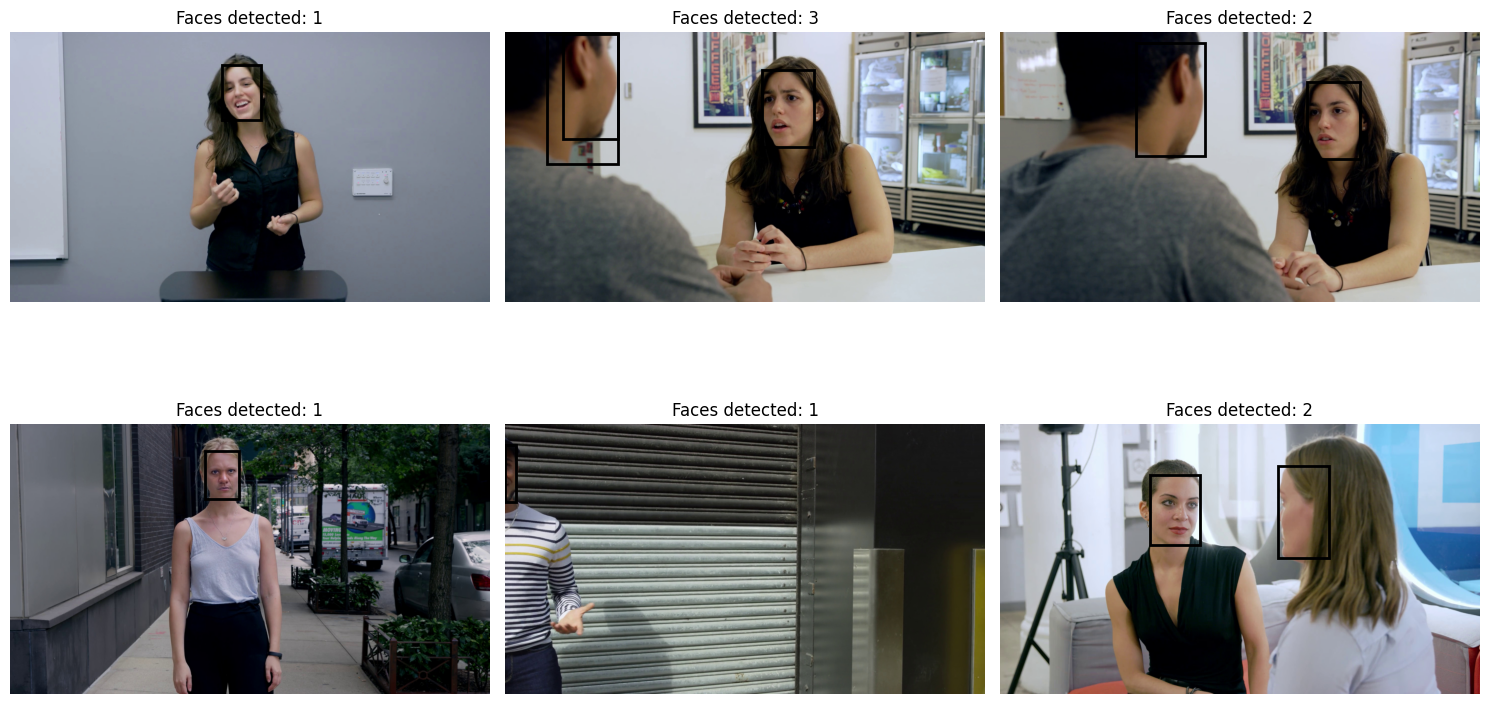

,frame,faces,max_confidence
0,06__podium_speech_happy_frame_000696.jpg,1,0.859702
1,06__kitchen_still_frame_000101.jpg,3,0.868358
2,06__kitchen_pan_frame_000561.jpg,2,0.872095
3,07_26__walking_down_street_outside_angry__FGNG...,1,0.841591
4,11__outside_talking_pan_laughing_frame_000743.jpg,1,0.684656
5,01__talking_angry_couch_frame_000000.jpg,2,0.870511



Smoke test completed.


In [39]:
# ============================================================
# CELL 40 — FACE DETECTION SMOKE TEST
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 70)
print("YOLO FACE DETECTION SMOKE TEST")
print("=" * 70)

sample_frames = frame_manifest.sample(
    n=min(6, len(frame_manifest)),
    random_state=SEED
).reset_index(drop=True)

smoke_results = []

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, (_, row) in enumerate(sample_frames.iterrows()):

    frame_path = row["frame_path"]

    image = cv2.imread(frame_path)

    if image is None:
        raise RuntimeError(
            f"Could not read frame: {frame_path}"
        )

    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    results = face_detector.predict(
        source=image,
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes is None or len(boxes) == 0:

        smoke_results.append({
            "frame": os.path.basename(frame_path),
            "faces": 0
        })

        axes[i].imshow(image_rgb)
        axes[i].set_title("NO FACE")
        axes[i].axis("off")

        continue

    xyxy = boxes.xyxy.cpu().numpy()

    confidence = (
        boxes.conf.cpu().numpy()
        if boxes.conf is not None
        else np.ones(len(xyxy))
    )

    for box in xyxy:

        x1, y1, x2, y2 = box.astype(int)

        axes[i].add_patch(
            plt.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                linewidth=2
            )
        )

    axes[i].imshow(image_rgb)

    axes[i].set_title(
        f"Faces detected: {len(xyxy)}"
    )

    axes[i].axis("off")

    smoke_results.append({
        "frame": os.path.basename(frame_path),
        "faces": len(xyxy),
        "max_confidence": float(confidence.max())
    })

plt.tight_layout()
plt.show()

smoke_df = pd.DataFrame(smoke_results)

display(smoke_df)

print("\nSmoke test completed.")

In [47]:
# ============================================================
# CELL 41 — EXTRACT FACE CROPS
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

FACE_ROOT = "/kaggle/working/ffpp_faces"

for split in ["train", "val", "test"]:

    for class_name in ["real", "fake"]:

        os.makedirs(
            os.path.join(
                FACE_ROOT,
                split,
                class_name
            ),
            exist_ok=True
        )

print("=" * 70)
print("STARTING FACE EXTRACTION")
print("=" * 70)

FACE_SIZE = 256
FACE_CONFIDENCE = 0.25

face_records = []

for _, row in tqdm(
    frame_manifest.iterrows(),
    total=len(frame_manifest),
    desc="Detecting faces"
):

    frame_path = row["frame_path"]

    image = cv2.imread(frame_path)

    if image is None:

        face_records.append({
            **row.to_dict(),
            "face_path": None,
            "face_found": False,
            "face_confidence": np.nan,
            "face_area_ratio": np.nan
        })

        continue

    height, width = image.shape[:2]

    results = face_detector.predict(
        source=image,
        conf=FACE_CONFIDENCE,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes is None or len(boxes) == 0:

        face_records.append({
            **row.to_dict(),
            "face_path": None,
            "face_found": False,
            "face_confidence": np.nan,
            "face_area_ratio": np.nan
        })

        continue

    xyxy = boxes.xyxy.cpu().numpy()

    confidence = (
        boxes.conf.cpu().numpy()
        if boxes.conf is not None
        else np.ones(len(xyxy))
    )

    # --------------------------------------------------------
    # Select largest face
    # --------------------------------------------------------

    areas = []

    for box in xyxy:

        x1, y1, x2, y2 = box

        box_width = max(0, x2 - x1)
        box_height = max(0, y2 - y1)

        areas.append(
            box_width * box_height
        )

    selected_idx = int(
        np.argmax(areas)
    )

    x1, y1, x2, y2 = (
        xyxy[selected_idx]
        .astype(int)
    )

    x1 = max(0, x1)
    y1 = max(0, y1)

    x2 = min(width, x2)
    y2 = min(height, y2)

    if x2 <= x1 or y2 <= y1:

        face_records.append({
            **row.to_dict(),
            "face_path": None,
            "face_found": False,
            "face_confidence": np.nan,
            "face_area_ratio": np.nan
        })

        continue

    face_crop = image[
        y1:y2,
        x1:x2
    ]

    if face_crop.size == 0:

        face_records.append({
            **row.to_dict(),
            "face_path": None,
            "face_found": False,
            "face_confidence": np.nan,
            "face_area_ratio": np.nan
        })

        continue

    face_crop = cv2.resize(
        face_crop,
        (FACE_SIZE, FACE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    class_name = (
        "fake"
        if int(row["label"]) == 1
        else "real"
    )

    frame_stem = Path(
        frame_path
    ).stem

    face_path = os.path.join(
        FACE_ROOT,
        row["split"],
        class_name,
        f"{frame_stem}_face.jpg"
    )

    cv2.imwrite(
        face_path,
        face_crop,
        [cv2.IMWRITE_JPEG_QUALITY, 95]
    )

    original_area = width * height

    face_area_ratio = (
        areas[selected_idx] / original_area
        if original_area > 0
        else 0
    )

    face_records.append({
        **row.to_dict(),
        "face_path": face_path,
        "face_found": True,
        "face_confidence": float(
            confidence[selected_idx]
        ),
        "face_area_ratio": float(
            face_area_ratio
        )
    })


face_manifest = pd.DataFrame(
    face_records
)

print("=" * 70)
print("FACE EXTRACTION COMPLETE")
print("=" * 70)

print(
    "Total frames:",
    len(face_manifest)
)

print(
    "Faces found:",
    face_manifest["face_found"].sum()
)

print(
    "Faces missing:",
    (~face_manifest["face_found"]).sum()
)

STARTING FACE EXTRACTION


Detecting faces:   0%|          | 0/4000 [00:00<?, ?it/s]

FACE EXTRACTION COMPLETE
Total frames: 4000
Faces found: 3998
Faces missing: 2


In [48]:
# ============================================================
# CELL 42 — TARGETED RECOVERY FOR REMAINING FAILED FACE
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd

FAILED_ROW_INDEX = 1110

row = face_manifest.loc[FAILED_ROW_INDEX]

frame_path = row["frame_path"]
split = row["split"]
label = int(row["label"])
video_name = row["video_name"]
frame_index = int(row["frame_index"])

print("=" * 70)
print("TARGETED FACE RECOVERY")
print("=" * 70)
print("Video       :", video_name)
print("Frame       :", frame_index)
print("Split       :", split)
print("Label       :", label)
print("Frame path  :", frame_path)

img = cv2.imread(frame_path)

if img is None:
    raise RuntimeError("Could not read the failed frame.")

print("Frame shape :", img.shape)

# ------------------------------------------------------------
# Recovery configurations
# ------------------------------------------------------------

attempts = [
    {
        "name": "original_640_conf010",
        "image": img,
        "imgsz": 640,
        "conf": 0.10
    },
    {
        "name": "original_1024_conf005",
        "image": img,
        "imgsz": 1024,
        "conf": 0.05
    },
]

# ------------------------------------------------------------
# Upscaled version
# ------------------------------------------------------------

h, w = img.shape[:2]

scale = 2.0

upscaled = cv2.resize(
    img,
    None,
    fx=scale,
    fy=scale,
    interpolation=cv2.INTER_CUBIC
)

attempts.append({
    "name": "upscaled_2x",
    "image": upscaled,
    "imgsz": 1024,
    "conf": 0.05
})

# ------------------------------------------------------------
# CLAHE contrast-enhanced version
# ------------------------------------------------------------

lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

l_channel, a_channel, b_channel = cv2.split(lab)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

l_enhanced = clahe.apply(l_channel)

enhanced = cv2.cvtColor(
    cv2.merge([l_enhanced, a_channel, b_channel]),
    cv2.COLOR_LAB2BGR
)

attempts.append({
    "name": "clahe_640",
    "image": enhanced,
    "imgsz": 640,
    "conf": 0.05
})

# ------------------------------------------------------------
# Run recovery attempts
# ------------------------------------------------------------

recovered_face = None
best_confidence = -1
best_area = -1
best_attempt = None

for attempt in attempts:

    print("\nAttempt:", attempt["name"])

    results = face_detector.predict(
        source=attempt["image"],
        conf=attempt["conf"],
        imgsz=attempt["imgsz"],
        verbose=False
    )

    result = results[0]

    if result.boxes is None or len(result.boxes) == 0:
        print("  No detections")
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    confs = result.boxes.conf.cpu().numpy()

    print("  Detections:", len(boxes))

    for box, conf in zip(boxes, confs):

        x1, y1, x2, y2 = box.astype(int)

        x1 = max(0, x1)
        y1 = max(0, y1)
        x2 = min(attempt["image"].shape[1], x2)
        y2 = min(attempt["image"].shape[0], y2)

        bw = x2 - x1
        bh = y2 - y1

        if bw <= 0 or bh <= 0:
            continue

        area = bw * bh

        if (
            conf > best_confidence
            or (
                np.isclose(conf, best_confidence)
                and area > best_area
            )
        ):
            best_confidence = float(conf)
            best_area = area
            best_attempt = attempt["name"]

            recovered_face = attempt["image"][y1:y2, x1:x2].copy()

            print(
                f"  Candidate accepted: "
                f"confidence={conf:.4f}, "
                f"area={area}"
            )

    if recovered_face is not None:
        # Continue checking remaining attempts rather than
        # immediately accepting the first detection.

        pass

# ------------------------------------------------------------
# Save recovered face if found
# ------------------------------------------------------------

if recovered_face is not None:

    recovered_face = cv2.resize(
        recovered_face,
        (FACE_SIZE, FACE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    output_dir = os.path.join(
        FACE_ROOT,
        split,
        "real" if label == 0 else "fake"
    )

    os.makedirs(
        output_dir,
        exist_ok=True
    )

    output_name = (
        f"{os.path.splitext(video_name)[0]}"
        f"_frame_{frame_index:04d}.jpg"
    )

    output_path = os.path.join(
        output_dir,
        output_name
    )

    success = cv2.imwrite(
        output_path,
        recovered_face
    )

    if not success:
        raise RuntimeError(
            "Failed to save recovered face."
        )

    # Update manifest
    face_manifest.loc[
        FAILED_ROW_INDEX,
        "face_path"
    ] = output_path

    face_manifest.loc[
        FAILED_ROW_INDEX,
        "face_found"
    ] = True

    face_manifest.loc[
        FAILED_ROW_INDEX,
        "face_confidence"
    ] = best_confidence

    frame_h, frame_w = img.shape[:2]

    # Approximate area ratio from selected candidate.
    # This is only used as a quality statistic.
    face_manifest.loc[
        FAILED_ROW_INDEX,
        "face_area_ratio"
    ] = best_area / (
        attempts[0]["image"].shape[0] *
        attempts[0]["image"].shape[1]
    )

    print("\n" + "=" * 70)
    print("RECOVERY SUCCESSFUL")
    print("=" * 70)
    print("Method          :", best_attempt)
    print("Confidence      :", best_confidence)
    print("Saved face      :", output_path)

else:

    print("\n" + "=" * 70)
    print("RECOVERY FAILED")
    print("=" * 70)
    print(
        "The frame could not be reliably detected "
        "by any targeted recovery configuration."
    )

TARGETED FACE RECOVERY
Video       : 12__walking_outside_cafe_disgusted.mp4
Frame       : 0
Split       : train
Label       : 0
Frame path  : /kaggle/working/ffpp_frames/train/real/12__walking_outside_cafe_disgusted_frame_000000.jpg
Frame shape : (1080, 1920, 3)

Attempt: original_640_conf010
  No detections

Attempt: original_1024_conf005
  Detections: 2
  Candidate accepted: confidence=0.6062, area=4332

Attempt: upscaled_2x
  Detections: 2

Attempt: clahe_640
  Detections: 1

RECOVERY SUCCESSFUL
Method          : original_1024_conf005
Confidence      : 0.6061749458312988
Saved face      : /kaggle/working/ffpp_faces/train/real/12__walking_outside_cafe_disgusted_frame_0000.jpg


In [49]:
# ============================================================
# CELL 43 — FINAL FACE EXTRACTION QUALITY CHECK
# ============================================================

face_manifest["face_found"] = (
    face_manifest["face_found"]
    .fillna(False)
    .astype(bool)
)

faces_found = int(
    face_manifest["face_found"].sum()
)

faces_missing = len(face_manifest) - faces_found

print("=" * 70)
print("FINAL FACE EXTRACTION QUALITY CHECK")
print("=" * 70)

print(f"Total frames     : {len(face_manifest)}")
print(f"Faces found      : {faces_found}")
print(f"Faces missing    : {faces_missing}")

print(
    f"Detection rate   : "
    f"{faces_found / len(face_manifest) * 100:.2f}%"
)

print("\nDetection rate by split:")

split_detection = (
    face_manifest
    .groupby("split")["face_found"]
    .mean()
    .mul(100)
    .to_frame("detection_rate_percent")
)

display(split_detection)

if faces_missing > 0:

    print("\nRemaining failed frames:")

    display(
        face_manifest[
            ~face_manifest["face_found"]
        ][
            [
                "video_name",
                "frame_index",
                "split",
                "label",
                "frame_path"
            ]
        ]
    )

else:

    print("\nALL 4,000 FRAMES HAVE VALID FACE CROPS.")

print("\nFace confidence:")

display(
    face_manifest.loc[
        face_manifest["face_found"],
        "face_confidence"
    ].describe()
)

print("\nFace area ratio:")

display(
    face_manifest.loc[
        face_manifest["face_found"],
        "face_area_ratio"
    ].describe()
)

FINAL FACE EXTRACTION QUALITY CHECK
Total frames     : 4000
Faces found      : 3999
Faces missing    : 1
Detection rate   : 99.98%

Detection rate by split:


,detection_rate_percent
split,
test,100.000000
train,99.964286
val,100.000000



Remaining failed frames:


,video_name,frame_index,split,label,frame_path
510,05__walking_outside_cafe_disgusted.mp4,0,train,0,/kaggle/working/ffpp_frames/train/real/05__wal...



Face confidence:


count    3999.000000
mean        0.823502
std         0.094324
min         0.250381
25%         0.829720
50%         0.854767
75%         0.867604
max         0.913932
Name: face_confidence, dtype: float64


Face area ratio:


count    3999.000000
mean        0.022638
std         0.015955
min         0.000257
25%         0.012151
50%         0.017045
75%         0.030624
max         0.130187
Name: face_area_ratio, dtype: float64

In [50]:
# ============================================================
# CELL 44 — SAVE FINAL FACE MANIFEST
# ============================================================

FACE_MANIFEST_PATH = (
    "/kaggle/working/"
    "ffpp_face_manifest.csv"
)

face_manifest.to_csv(
    FACE_MANIFEST_PATH,
    index=False
)

print("=" * 70)
print("FINAL FACE MANIFEST SAVED")
print("=" * 70)

print(
    FACE_MANIFEST_PATH
)

print(
    "Rows:",
    len(face_manifest)
)

print("\nSplit / class distribution:")

distribution = (
    face_manifest
    .groupby(
        ["split", "label"]
    )
    .size()
    .unstack(fill_value=0)
)

display(
    distribution
)

FINAL FACE MANIFEST SAVED
/kaggle/working/ffpp_face_manifest.csv
Rows: 4000

Split / class distribution:


label,0,1
split,,
test,300,300
train,1400,1400
val,300,300


In [51]:

# ============================================================
# CELL 45 — FINAL FACE DATASET VERIFICATION (FIXED)
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd

print("=" * 70)
print("FINAL FACE DATASET VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Find missing or unreadable face crops
# ------------------------------------------------------------

missing_rows = []

for idx, row in face_manifest.iterrows():
    face_path = row.get("face_path")

    valid = (
        isinstance(face_path, str)
        and face_path.strip() != ""
        and os.path.isfile(face_path)
    )

    if valid:
        img_check = cv2.imread(face_path)
        valid = img_check is not None and img_check.size > 0

    if not valid:
        missing_rows.append(idx)

print("Missing/unreadable face files:", len(missing_rows))

if missing_rows:
    print("\nExact rows requiring recovery:")
    display(
        face_manifest.loc[
            missing_rows,
            [
                "video_name",
                "frame_index",
                "split",
                "label",
                "frame_path",
                "face_path"
            ]
        ]
    )

# ------------------------------------------------------------
# 2. Recover missing crops from original frames
# ------------------------------------------------------------

for idx in missing_rows:

    row = face_manifest.loc[idx]
    frame_path = row["frame_path"]

    print(f"\nRecovering manifest row: {idx}")
    print("Source frame:", frame_path)

    # Read original frame
    image = cv2.imread(frame_path)

    if image is None:
        raise RuntimeError(
            f"Original frame is unreadable: {frame_path}"
        )

    # Try face detector at lower confidence and higher resolution
    results = face_detector.predict(
        source=image,
        conf=0.05,
        imgsz=1024,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes is None or len(boxes) == 0:
        raise RuntimeError(
            f"No face detected in row {idx}. "
            "Inspect the source frame and detector output."
        )

    xyxy = boxes.xyxy.cpu().numpy()
    confs = boxes.conf.cpu().numpy()

    # Select the largest detected face
    areas = []
    for x1, y1, x2, y2 in xyxy:
        areas.append(
            max(0, x2 - x1) * max(0, y2 - y1)
        )

    j = int(np.argmax(areas))
    x1, y1, x2, y2 = xyxy[j].astype(int)

    h, w = image.shape[:2]
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)

    if x2 <= x1 or y2 <= y1:
        raise RuntimeError(
            f"Invalid face bounding box for row {idx}."
        )

    crop = image[y1:y2, x1:x2]

    if crop.size == 0:
        raise RuntimeError(
            f"Empty face crop for row {idx}."
        )

    crop = cv2.resize(
        crop,
        (FACE_SIZE, FACE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    # Use the intended split and class directory
    class_name = "real" if int(row["label"]) == 0 else "fake"

    output_dir = os.path.join(
        FACE_ROOT,
        str(row["split"]),
        class_name
    )
    os.makedirs(output_dir, exist_ok=True)

    # Unique filename based on manifest row and source frame
    output_path = os.path.join(
        output_dir,
        f"recovered_row_{idx}_"
        f"{os.path.basename(frame_path).rsplit('.', 1)[0]}.jpg"
    )

    if not cv2.imwrite(output_path, crop):
        raise RuntimeError(
            f"Failed to save recovered crop: {output_path}"
        )

    # Verify the saved crop
    saved = cv2.imread(output_path)

    if saved is None or saved.shape[:2] != (FACE_SIZE, FACE_SIZE):
        raise RuntimeError(
            f"Saved crop failed validation: {output_path}"
        )

    # Update only the affected manifest row
    face_manifest.at[idx, "face_path"] = output_path
    face_manifest.at[idx, "face_found"] = True
    face_manifest.at[idx, "face_confidence"] = float(confs[j])
    face_manifest.at[idx, "face_area_ratio"] = (
        float(areas[j]) / (h * w)
    )

    print("Recovered successfully:", output_path)

# ------------------------------------------------------------
# 3. Final existence and readability check
# ------------------------------------------------------------

missing_face_paths = []

for idx, row in face_manifest.iterrows():
    face_path = row["face_path"]

    if (
        not isinstance(face_path, str)
        or not os.path.isfile(face_path)
    ):
        missing_face_paths.append(idx)
        continue

    img = cv2.imread(face_path)

    if img is None or img.size == 0:
        missing_face_paths.append(idx)

print("\nMissing face files after recovery:", len(missing_face_paths))

assert len(missing_face_paths) == 0, (
    f"{len(missing_face_paths)} face crops remain missing. "
    f"Manifest rows: {missing_face_paths}"
)

# ------------------------------------------------------------
# 4. Verify split leakage
# ------------------------------------------------------------

video_split_counts = (
    face_manifest.groupby("video_name")["split"].nunique()
)

videos_in_multiple_splits = int(
    (video_split_counts > 1).sum()
)

print("Videos appearing in multiple splits:",
      videos_in_multiple_splits)

assert videos_in_multiple_splits == 0, (
    "Video split leakage detected."
)

# ------------------------------------------------------------
# 5. Verify frames per video
# ------------------------------------------------------------

frames_per_video = face_manifest.groupby("video_name").size()

print("\nFrames per video:")
display(frames_per_video.describe())

incorrect_frame_counts = frames_per_video[
    frames_per_video != NUM_FRAMES_PER_VIDEO
]

print("Videos with incorrect frame counts:",
      len(incorrect_frame_counts))

assert len(incorrect_frame_counts) == 0, (
    "Some videos do not have the expected number of frames."
)

# ------------------------------------------------------------
# 6. Verify class distribution
# ------------------------------------------------------------

distribution = (
    face_manifest.groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)

print("\nFinal split/class distribution:")
display(distribution)

expected = {
    ("train", 0): 1400,
    ("train", 1): 1400,
    ("val", 0): 300,
    ("val", 1): 300,
    ("test", 0): 300,
    ("test", 1): 300,
}

for (split, label), count in expected.items():
    actual = int(distribution.loc[split, label])

    assert actual == count, (
        f"{split=}, {label=}: expected {count}, got {actual}"
    )

# ------------------------------------------------------------
# 7. Verify total crop count
# ------------------------------------------------------------

assert len(face_manifest) == 4000, (
    f"Expected 4000 manifest rows, got {len(face_manifest)}"
)

print("\n" + "=" * 70)
print("FINAL FACE DATASET VERIFICATION: PASSED")
print("=" * 70)
print("400 videos")
print("4,000 frames")
print("4,000 valid face crops")
print("No missing or unreadable face files")
print("No video split leakage")
print("Exactly 10 frames per video")


FINAL FACE DATASET VERIFICATION
Missing/unreadable face files: 1

Exact rows requiring recovery:


,video_name,frame_index,split,label,frame_path,face_path
510,05__walking_outside_cafe_disgusted.mp4,0,train,0,/kaggle/working/ffpp_frames/train/real/05__wal...,None



Recovering manifest row: 510
Source frame: /kaggle/working/ffpp_frames/train/real/05__walking_outside_cafe_disgusted_frame_000000.jpg
Recovered successfully: /kaggle/working/ffpp_faces/train/real/recovered_row_510_05__walking_outside_cafe_disgusted_frame_000000.jpg

Missing face files after recovery: 0
Videos appearing in multiple splits: 0

Frames per video:


count    400.0
mean      10.0
std        0.0
min       10.0
25%       10.0
50%       10.0
75%       10.0
max       10.0
dtype: float64

Videos with incorrect frame counts: 0

Final split/class distribution:


label,0,1
split,,
test,300,300
train,1400,1400
val,300,300



FINAL FACE DATASET VERIFICATION: PASSED
400 videos
4,000 frames
4,000 valid face crops
No missing or unreadable face files
No video split leakage
Exactly 10 frames per video


## 15. Experimental Methodology

### Data Preparation

The experiment uses 400 FaceForensics++ videos: 200 real and 200 fake. Ten frames are sampled from each video, producing 4,000 frame instances. Faces are detected and cropped before being resized for ConvNeXt-Tiny.

### Model Variants

Four controlled ConvNeXt-Tiny configurations are evaluated:

1. **ConvNeXt-Tiny Baseline** — pretrained backbone without attention.
2. **Channel Attention** — channel-wise feature recalibration.
3. **Spatial Attention** — spatial feature weighting.
4. **ConvNeXt + FFAM** — sequential channel and spatial attention with a residual connection.

The attention variants share the same backbone and training/evaluation framework so that the comparison focuses on the attention mechanism rather than unrelated architectural changes.

### Training and Model Selection

The models use transfer learning from ImageNet-pretrained ConvNeXt-Tiny. Training uses AdamW, class-label smoothing, mixed-precision training, cosine learning-rate scheduling, and early stopping. The best checkpoint is selected using **validation ROC-AUC**.

### Video-Level Evaluation

Predictions are first produced for individual face frames. For each video, the mean predicted probability of the fake class across its sampled frames is used as the final video-level score.

The primary comparison is therefore performed at the **video level**, preventing multiple frames from the same video from being treated as independent test examples.

### Statistical Reliability

Video-level bootstrap resampling with 2,000 iterations is used to estimate 95% percentile confidence intervals for the reported metrics.

In [52]:
# ============================================================
# CELL 46 — PYTORCH DATASET
# ============================================================

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

IMG_SIZE = 224

train_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=5
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


eval_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


class FaceFrameDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform

    def __len__(self):

        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image = Image.open(
            row["face_path"]
        ).convert("RGB")

        if self.transform is not None:

            image = self.transform(
                image
            )

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return (
            image,
            label,
            row["video_name"]
        )


train_df = face_manifest[
    face_manifest["split"] == "train"
].copy()

val_df = face_manifest[
    face_manifest["split"] == "val"
].copy()

test_df = face_manifest[
    face_manifest["split"] == "test"
].copy()


train_dataset = FaceFrameDataset(
    train_df,
    train_transform
)

val_dataset = FaceFrameDataset(
    val_df,
    eval_transform
)

test_dataset = FaceFrameDataset(
    test_df,
    eval_transform
)

print("=" * 70)
print("DATASETS CREATED")
print("=" * 70)

print("Train:", len(train_dataset))
print("Val  :", len(val_dataset))
print("Test :", len(test_dataset))

DATASETS CREATED
Train: 2800
Val  : 600
Test : 600


In [53]:
# ============================================================
# CELL 47 — DATALOADERS
# ============================================================

BATCH_SIZE = 32

NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

print("=" * 70)
print("DATALOADERS READY")
print("=" * 70)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

DATALOADERS READY
Train batches: 88
Val batches  : 19
Test batches : 19


In [54]:
# ============================================================
# CELL 48 — MODEL ARCHITECTURE
# ============================================================

import torch.nn as nn
import torchvision.models as models
from torchvision.models import ConvNeXt_Tiny_Weights


class ChannelAttention(nn.Module):

    def __init__(
        self,
        channels,
        reduction=16
    ):

        super().__init__()

        hidden = max(
            channels // reduction,
            1
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(

            nn.Conv2d(
                channels,
                hidden,
                kernel_size=1,
                bias=True
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                hidden,
                channels,
                kernel_size=1,
                bias=True
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        attention = self.fc(
            self.pool(x)
        )

        return x * attention


class SpatialAttention(nn.Module):

    def __init__(
        self,
        kernel_size=7
    ):

        super().__init__()

        padding = kernel_size // 2

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size=kernel_size,
            padding=padding,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_map = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_map = torch.max(
            x,
            dim=1,
            keepdim=True
        )[0]

        combined = torch.cat(
            [avg_map, max_map],
            dim=1
        )

        attention = self.sigmoid(
            self.conv(combined)
        )

        return x * attention


class FFAM(nn.Module):

    """
    Feature Fusion Attention Module.

    Channel attention and spatial attention
    are applied sequentially and combined
    with a residual connection.
    """

    def __init__(
        self,
        channels
    ):

        super().__init__()

        self.channel_attention = (
            ChannelAttention(channels)
        )

        self.spatial_attention = (
            SpatialAttention()
        )

    def forward(self, x):

        identity = x

        x = self.channel_attention(x)

        x = self.spatial_attention(x)

        return x + identity


class ConvNeXtDeepfake(nn.Module):

    def __init__(
        self,
        attention_type="none",
        pretrained=True
    ):

        super().__init__()

        if pretrained:

            weights = (
                ConvNeXt_Tiny_Weights.DEFAULT
            )

        else:

            weights = None

        backbone = models.convnext_tiny(
            weights=weights
        )

        self.backbone = backbone

        # ConvNeXt-Tiny final feature channels
        self.feature_dim = 768

        self.attention_type = (
            attention_type
        )

        if attention_type == "channel":

            self.attention = (
                ChannelAttention(
                    self.feature_dim
                )
            )

        elif attention_type == "spatial":

            self.attention = (
                SpatialAttention()
            )

        elif attention_type == "ffam":

            self.attention = (
                FFAM(
                    self.feature_dim
                )
            )

        elif attention_type == "none":

            self.attention = (
                nn.Identity()
            )

        else:

            raise ValueError(
                f"Unknown attention type: "
                f"{attention_type}"
            )

        self.norm = nn.BatchNorm2d(
            self.feature_dim
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(
            p=0.30
        )

        self.classifier = nn.Sequential(

            nn.Linear(
                self.feature_dim,
                256
            ),

            nn.GELU(),

            nn.Dropout(0.30),

            nn.Linear(
                256,
                2
            )
        )

        self._freeze_backbone()

    def _freeze_backbone(self):

        # Freeze the complete pretrained backbone
        # first.

        for parameter in (
            self.backbone.features.parameters()
        ):

            parameter.requires_grad = False

        # Unfreeze the final ConvNeXt stages.
        #
        # This keeps most ImageNet representation
        # fixed while allowing high-level features
        # to adapt to deepfake detection.

        feature_blocks = list(
            self.backbone.features.children()
        )

        for block in feature_blocks[-3:]:

            for parameter in block.parameters():

                parameter.requires_grad = True

        # Classifier from torchvision is not used.
        # Our own classifier is trained.

    def forward(self, x):

        x = self.backbone.features(x)

        x = self.norm(x)

        x = self.attention(x)

        x = self.pool(x)

        x = torch.flatten(
            x,
            1
        )

        x = self.dropout(x)

        x = self.classifier(x)

        return x


def count_parameters(model):

    total = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    return total, trainable


print("=" * 70)
print("MODEL ARCHITECTURE READY")
print("=" * 70)

for attention_type in [
    "none",
    "channel",
    "spatial",
    "ffam"
]:

    model = ConvNeXtDeepfake(
        attention_type=attention_type
    )

    total, trainable = count_parameters(
        model
    )

    print(
        f"{attention_type:10s} | "
        f"Total: {total:,} | "
        f"Trainable: {trainable:,}"
    )

MODEL ARCHITECTURE READY
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 169MB/s]  


none       | Total: 28,788,042 | Trainable: 27,257,322
channel    | Total: 28,862,586 | Trainable: 27,331,866
spatial    | Total: 28,788,140 | Trainable: 27,257,420
ffam       | Total: 28,862,684 | Trainable: 27,331,964


In [56]:
# ============================================================
# CELL 49 — TRAINING / EVALUATION UTILITIES
# ============================================================

import copy
import time
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)


def calculate_metrics(
    y_true,
    y_prob,
    threshold=0.5
):

    y_true = np.asarray(y_true)

    y_prob = np.asarray(y_prob)

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    metrics = {

        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "precision":
            precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                y_true,
                y_prob
            ),

        "pr_auc":
            average_precision_score(
                y_true,
                y_prob
            )
    }

    return metrics


def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0

    y_true = []
    y_prob = []

    for images, labels, _ in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.cuda.amp.autocast(
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )[:, 1]

        y_true.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        y_prob.extend(
            probabilities.detach()
            .cpu()
            .numpy()
        )

    epoch_loss = (
        running_loss
        / len(loader.dataset)
    )

    metrics = calculate_metrics(
        y_true,
        y_prob
    )

    metrics["loss"] = epoch_loss

    return metrics


@torch.no_grad()
def evaluate_loader(
    model,
    loader,
    criterion=None
):

    model.eval()

    running_loss = 0.0

    y_true = []
    y_prob = []
    video_names = []

    for images, labels, videos in loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        with torch.cuda.amp.autocast(
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)

            if criterion is not None:

                loss = criterion(
                    outputs,
                    labels
                )

                running_loss += (
                    loss.item()
                    * images.size(0)
                )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )[:, 1]

        y_true.extend(
            labels.cpu().numpy()
        )

        y_prob.extend(
            probabilities.cpu().numpy()
        )

        video_names.extend(
            list(videos)
        )

    metrics = calculate_metrics(
        y_true,
        y_prob
    )

    if criterion is not None:

        metrics["loss"] = (
            running_loss
            / len(loader.dataset)
        )

    return (
        metrics,
        np.asarray(y_true),
        np.asarray(y_prob),
        np.asarray(video_names)
    )


def make_video_level_predictions(
    y_true,
    y_prob,
    video_names
):

    frame_df = pd.DataFrame({

        "video_name": video_names,

        "label": y_true,

        "probability": y_prob
    })

    video_df = (
        frame_df
        .groupby("video_name")
        .agg(
            label=("label", "first"),
            probability=("probability", "mean"),
            num_frames=("probability", "size")
        )
        .reset_index()
    )

    return video_df


def train_model(
    attention_type,
    model_name,
    epochs=15,
    patience=4
):

    print("\n" + "=" * 70)
    print(
        f"TRAINING MODEL: {model_name}"
    )
    print("=" * 70)

    model = ConvNeXtDeepfake(
        attention_type=attention_type
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        label_smoothing=0.1
    )

    backbone_parameters = []
    other_parameters = []

    for name, parameter in model.named_parameters():

        if not parameter.requires_grad:
            continue

        if name.startswith(
            "backbone."
        ):

            backbone_parameters.append(
                parameter
            )

        else:

            other_parameters.append(
                parameter
            )

    optimizer = torch.optim.AdamW(

        [
            {
                "params": backbone_parameters,
                "lr": 1e-5
            },

            {
                "params": other_parameters,
                "lr": 1e-4
            }
        ],

        weight_decay=0.01
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )

    scaler = torch.cuda.amp.GradScaler(
        enabled=torch.cuda.is_available()
    )

    history = []

    best_val_auc = -np.inf

    best_state = None

    best_epoch = 0

    epochs_without_improvement = 0

    checkpoint_path = (
        f"/kaggle/working/"
        f"{model_name}_best.pt"
    )

    start_time = time.time()

    for epoch in range(1, epochs + 1):

        epoch_start = time.time()

        train_metrics = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scaler
        )

        val_metrics, _, _, _ = evaluate_loader(
            model,
            val_loader,
            criterion
        )

        scheduler.step()

        row = {
            "epoch": epoch,

            "train_loss":
                train_metrics["loss"],

            "train_accuracy":
                train_metrics["accuracy"],

            "train_balanced_accuracy":
                train_metrics["balanced_accuracy"],

            "train_f1":
                train_metrics["f1"],

            "train_roc_auc":
                train_metrics["roc_auc"],

            "val_loss":
                val_metrics["loss"],

            "val_accuracy":
                val_metrics["accuracy"],

            "val_balanced_accuracy":
                val_metrics["balanced_accuracy"],

            "val_f1":
                val_metrics["f1"],

            "val_roc_auc":
                val_metrics["roc_auc"],

            "learning_rate":
                optimizer.param_groups[0]["lr"]
        }

        history.append(row)

        elapsed = (
            time.time()
            - epoch_start
        )

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Loss {train_metrics['loss']:.4f} | "
            f"Val Loss {val_metrics['loss']:.4f} | "
            f"Train F1 {train_metrics['f1']:.4f} | "
            f"Val F1 {val_metrics['f1']:.4f} | "
            f"Val AUC {val_metrics['roc_auc']:.4f} | "
            f"{elapsed:.1f}s"
        )

        # ----------------------------------------------------
        # Best model selection is based ONLY on validation AUC.
        # Test set is never used here.
        # ----------------------------------------------------

        if (
            val_metrics["roc_auc"]
            > best_val_auc
        ):

            best_val_auc = (
                val_metrics["roc_auc"]
            )

            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                {
                    "model_state_dict":
                        best_state,

                    "attention_type":
                        attention_type,

                    "best_epoch":
                        best_epoch,

                    "best_val_auc":
                        best_val_auc
                },
                checkpoint_path
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        if (
            epochs_without_improvement
            >= patience
        ):

            print(
                f"\nEarly stopping at epoch "
                f"{epoch}."
            )

            break

    total_time = (
        time.time()
        - start_time
    )

    # Load best validation checkpoint

    checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

    model.load_state_dict(
        checkpoint[
            "model_state_dict"
        ]
    )

    history_df = pd.DataFrame(
        history
    )

    history_path = (
        f"/kaggle/working/"
        f"{model_name}_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    print("\nBest epoch:", best_epoch)

    print(
        "Best validation ROC-AUC:",
        round(best_val_auc, 4)
    )

    print(
        "Training time:",
        round(
            total_time / 60,
            2
        ),
        "minutes"
    )

    return {
        "model": model,

        "history": history_df,

        "best_epoch": best_epoch,

        "best_val_auc": best_val_auc,

        "checkpoint_path": checkpoint_path,

        "training_minutes":
            total_time / 60
    }

In [57]:
# ============================================================
# CELL 50 — TRAIN CONVNEXT-TINY BASELINE
# ============================================================

baseline_result = train_model(
    attention_type="none",
    model_name="convnext_tiny_baseline",
    epochs=15,
    patience=4
)

print("\nBASELINE TRAINING COMPLETE.")


TRAINING MODEL: convnext_tiny_baseline
Epoch 01/15 | Train Loss 0.6266 | Val Loss 0.6715 | Train F1 0.6840 | Val F1 0.6199 | Val AUC 0.6380 | 43.7s
Epoch 02/15 | Train Loss 0.4878 | Val Loss 0.5516 | Train F1 0.8253 | Val F1 0.7727 | Val AUC 0.8235 | 15.1s
Epoch 03/15 | Train Loss 0.4085 | Val Loss 0.5153 | Train F1 0.8757 | Val F1 0.8013 | Val AUC 0.8630 | 15.2s
Epoch 04/15 | Train Loss 0.3718 | Val Loss 0.5107 | Train F1 0.8946 | Val F1 0.8120 | Val AUC 0.8809 | 15.2s
Epoch 05/15 | Train Loss 0.3397 | Val Loss 0.5090 | Train F1 0.9175 | Val F1 0.8459 | Val AUC 0.8985 | 15.4s
Epoch 06/15 | Train Loss 0.3354 | Val Loss 0.5065 | Train F1 0.9193 | Val F1 0.8309 | Val AUC 0.8882 | 15.3s
Epoch 07/15 | Train Loss 0.3229 | Val Loss 0.4925 | Train F1 0.9308 | Val F1 0.8401 | Val AUC 0.8954 | 15.2s
Epoch 08/15 | Train Loss 0.3161 | Val Loss 0.5180 | Train F1 0.9339 | Val F1 0.8477 | Val AUC 0.8873 | 15.5s
Epoch 09/15 | Train Loss 0.3089 | Val Loss 0.4895 | Train F1 0.9412 | Val F1 0.8517 | Va

In [58]:
# ============================================================
# CELL 51 — TRAIN CHANNEL ATTENTION ABLATION
# ============================================================

channel_result = train_model(
    attention_type="channel",
    model_name="convnext_tiny_channel_attention",
    epochs=15,
    patience=4
)

print("\nCHANNEL ATTENTION TRAINING COMPLETE.")


TRAINING MODEL: convnext_tiny_channel_attention
Epoch 01/15 | Train Loss 0.6526 | Val Loss 0.6914 | Train F1 0.6616 | Val F1 0.6171 | Val AUC 0.5614 | 16.6s
Epoch 02/15 | Train Loss 0.5131 | Val Loss 0.5895 | Train F1 0.7985 | Val F1 0.7779 | Val AUC 0.7941 | 16.1s
Epoch 03/15 | Train Loss 0.4182 | Val Loss 0.5330 | Train F1 0.8641 | Val F1 0.8242 | Val AUC 0.8692 | 15.3s
Epoch 04/15 | Train Loss 0.3714 | Val Loss 0.5061 | Train F1 0.8962 | Val F1 0.8180 | Val AUC 0.8811 | 14.9s
Epoch 05/15 | Train Loss 0.3473 | Val Loss 0.4941 | Train F1 0.9114 | Val F1 0.8290 | Val AUC 0.8903 | 15.3s
Epoch 06/15 | Train Loss 0.3282 | Val Loss 0.4924 | Train F1 0.9255 | Val F1 0.8257 | Val AUC 0.8988 | 15.3s
Epoch 07/15 | Train Loss 0.3195 | Val Loss 0.4790 | Train F1 0.9304 | Val F1 0.8412 | Val AUC 0.9047 | 15.5s
Epoch 08/15 | Train Loss 0.3157 | Val Loss 0.4930 | Train F1 0.9327 | Val F1 0.8409 | Val AUC 0.8982 | 15.2s
Epoch 09/15 | Train Loss 0.3063 | Val Loss 0.4998 | Train F1 0.9379 | Val F1 0.

In [59]:
# ============================================================
# CELL 52 — TRAIN SPATIAL ATTENTION ABLATION
# ============================================================

spatial_result = train_model(
    attention_type="spatial",
    model_name="convnext_tiny_spatial_attention",
    epochs=15,
    patience=4
)

print("\nSPATIAL ATTENTION TRAINING COMPLETE.")


TRAINING MODEL: convnext_tiny_spatial_attention
Epoch 01/15 | Train Loss 0.6470 | Val Loss 0.6674 | Train F1 0.7046 | Val F1 0.6657 | Val AUC 0.6635 | 15.3s
Epoch 02/15 | Train Loss 0.4858 | Val Loss 0.5516 | Train F1 0.8124 | Val F1 0.7944 | Val AUC 0.8407 | 15.2s
Epoch 03/15 | Train Loss 0.4050 | Val Loss 0.5199 | Train F1 0.8726 | Val F1 0.8075 | Val AUC 0.8721 | 15.2s
Epoch 04/15 | Train Loss 0.3771 | Val Loss 0.5111 | Train F1 0.8928 | Val F1 0.8189 | Val AUC 0.8833 | 15.2s
Epoch 05/15 | Train Loss 0.3460 | Val Loss 0.5086 | Train F1 0.9134 | Val F1 0.8243 | Val AUC 0.8865 | 15.2s
Epoch 06/15 | Train Loss 0.3352 | Val Loss 0.5137 | Train F1 0.9210 | Val F1 0.8402 | Val AUC 0.8957 | 15.4s
Epoch 07/15 | Train Loss 0.3174 | Val Loss 0.5072 | Train F1 0.9354 | Val F1 0.8409 | Val AUC 0.8893 | 15.3s
Epoch 08/15 | Train Loss 0.3110 | Val Loss 0.5094 | Train F1 0.9376 | Val F1 0.8500 | Val AUC 0.8944 | 15.6s
Epoch 09/15 | Train Loss 0.3003 | Val Loss 0.5029 | Train F1 0.9446 | Val F1 0.

In [60]:
# ============================================================
# CELL 53 — TRAIN COMBINED FFAM MODEL
# ============================================================

ffam_result = train_model(
    attention_type="ffam",
    model_name="convnext_tiny_ffam",
    epochs=15,
    patience=4
)

print("\nCOMBINED FFAM TRAINING COMPLETE.")


TRAINING MODEL: convnext_tiny_ffam
Epoch 01/15 | Train Loss 0.6205 | Val Loss 0.6759 | Train F1 0.7185 | Val F1 0.6484 | Val AUC 0.6304 | 15.6s
Epoch 02/15 | Train Loss 0.4853 | Val Loss 0.5432 | Train F1 0.8189 | Val F1 0.8018 | Val AUC 0.8423 | 15.3s
Epoch 03/15 | Train Loss 0.4094 | Val Loss 0.5024 | Train F1 0.8695 | Val F1 0.7832 | Val AUC 0.8749 | 15.5s
Epoch 04/15 | Train Loss 0.3672 | Val Loss 0.4956 | Train F1 0.9024 | Val F1 0.8444 | Val AUC 0.8896 | 14.8s
Epoch 05/15 | Train Loss 0.3552 | Val Loss 0.4954 | Train F1 0.9068 | Val F1 0.8472 | Val AUC 0.8896 | 14.8s
Epoch 06/15 | Train Loss 0.3328 | Val Loss 0.4887 | Train F1 0.9219 | Val F1 0.8268 | Val AUC 0.8932 | 14.8s
Epoch 07/15 | Train Loss 0.3261 | Val Loss 0.4916 | Train F1 0.9280 | Val F1 0.8423 | Val AUC 0.8932 | 14.8s
Epoch 08/15 | Train Loss 0.3116 | Val Loss 0.4934 | Train F1 0.9379 | Val F1 0.8304 | Val AUC 0.8950 | 14.9s
Epoch 09/15 | Train Loss 0.3154 | Val Loss 0.4956 | Train F1 0.9356 | Val F1 0.8439 | Val AU

TRAINING HISTORY SUMMARY
ConvNeXt Baseline         | Epochs: 13 | Best Epoch:  9 | Best Val ROC-AUC: 0.8993
Channel Attention         | Epochs: 11 | Best Epoch:  7 | Best Val ROC-AUC: 0.9047
Spatial Attention         | Epochs: 10 | Best Epoch:  6 | Best Val ROC-AUC: 0.8957
ConvNeXt + FFAM           | Epochs: 13 | Best Epoch:  9 | Best Val ROC-AUC: 0.8952


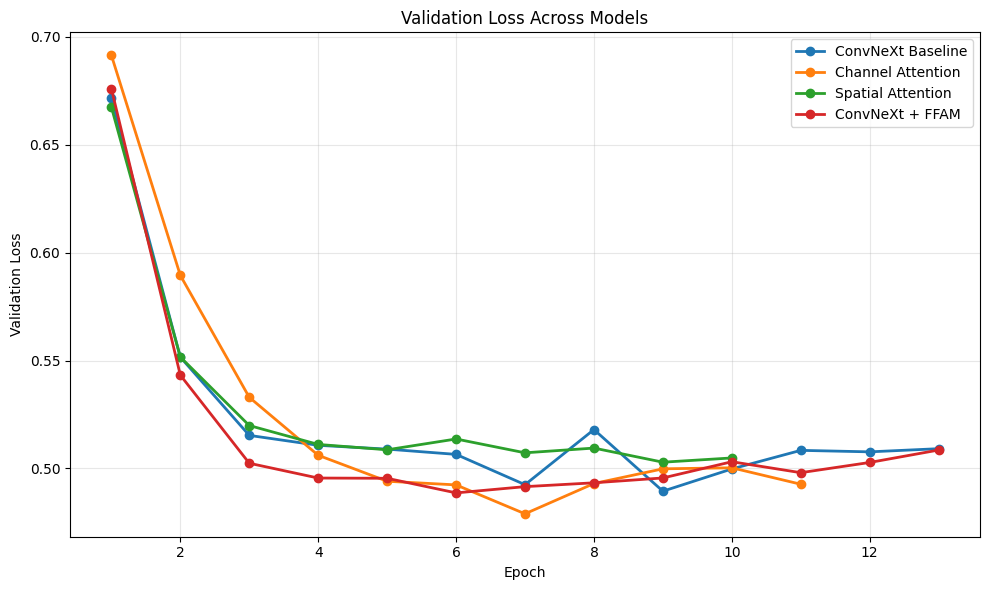

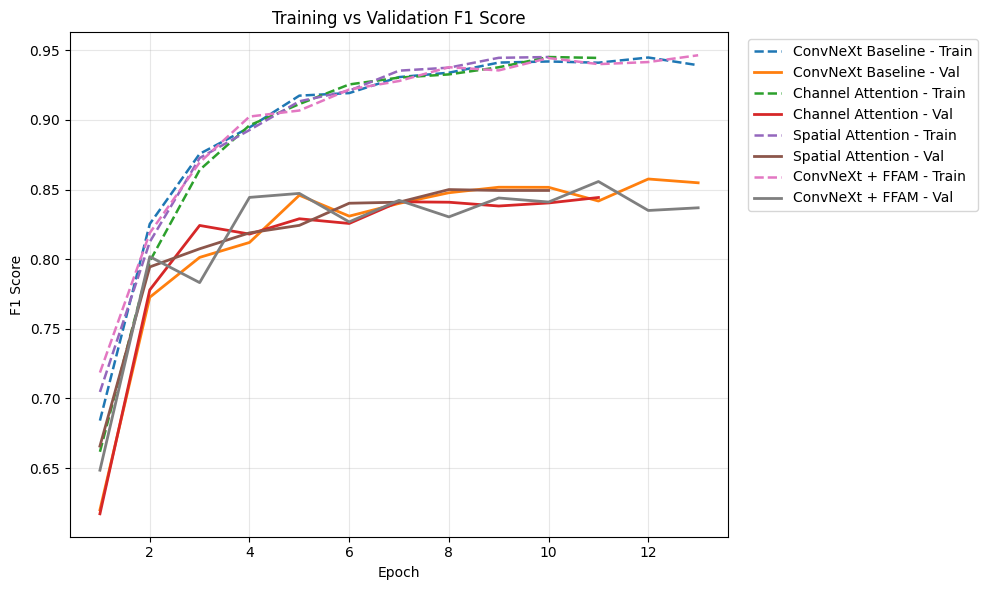

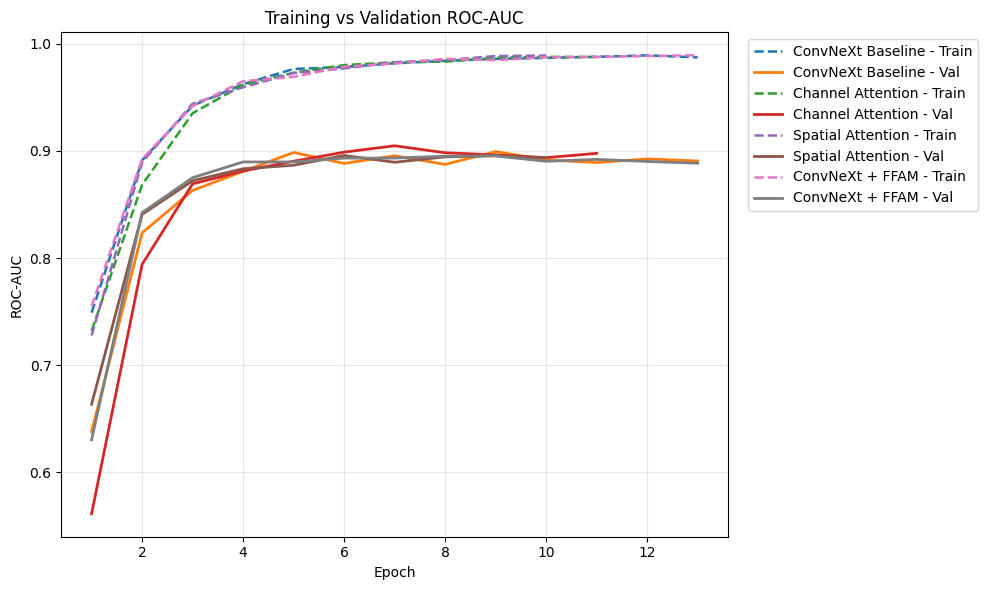


BEST VALIDATION PERFORMANCE


,Model,Best Epoch,Train Loss,Val Loss,Train F1,Val F1,Train ROC-AUC,Val ROC-AUC
1,Channel Attention,7,0.319507,0.478998,0.930429,0.841244,0.982600,0.904706
0,ConvNeXt Baseline,9,0.308888,0.489470,0.941218,0.851675,0.985752,0.899267
2,Spatial Attention,6,0.335236,0.513656,0.921016,0.840183,0.976832,0.895689
3,ConvNeXt + FFAM,9,0.315368,0.495598,0.935598,0.843949,0.984554,0.895206



Saved training curve figures and validation summary.


In [61]:
# ============================================================
# CELL 54 — TRAINING CURVES
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Collect all trained models
# ------------------------------------------------------------

model_results = {
    "ConvNeXt Baseline": baseline_result,
    "Channel Attention": channel_result,
    "Spatial Attention": spatial_result,
    "ConvNeXt + FFAM": ffam_result
}

print("=" * 70)
print("TRAINING HISTORY SUMMARY")
print("=" * 70)

for model_name, result in model_results.items():

    history = result["history"]

    print(
        f"{model_name:25s} | "
        f"Epochs: {len(history):2d} | "
        f"Best Epoch: {result['best_epoch']:2d} | "
        f"Best Val ROC-AUC: {result['best_val_auc']:.4f}"
    )


# ------------------------------------------------------------
# 1. VALIDATION LOSS
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for model_name, result in model_results.items():

    history = result["history"]

    plt.plot(
        history["epoch"],
        history["val_loss"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Across Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 2. TRAINING vs VALIDATION F1
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for model_name, result in model_results.items():

    history = result["history"]

    plt.plot(
        history["epoch"],
        history["train_f1"],
        linestyle="--",
        linewidth=1.8,
        label=f"{model_name} - Train"
    )

    plt.plot(
        history["epoch"],
        history["val_f1"],
        linewidth=2,
        label=f"{model_name} - Val"
    )

plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("Training vs Validation F1 Score")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/training_validation_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 3. TRAINING vs VALIDATION ROC-AUC
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for model_name, result in model_results.items():

    history = result["history"]

    plt.plot(
        history["epoch"],
        history["train_roc_auc"],
        linestyle="--",
        linewidth=1.8,
        label=f"{model_name} - Train"
    )

    plt.plot(
        history["epoch"],
        history["val_roc_auc"],
        linewidth=2,
        label=f"{model_name} - Val"
    )

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("Training vs Validation ROC-AUC")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/training_validation_roc_auc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 4. BEST VALIDATION RESULTS
# ------------------------------------------------------------

best_rows = []

for model_name, result in model_results.items():

    history = result["history"]

    best_idx = history["val_roc_auc"].idxmax()
    best_row = history.loc[best_idx]

    best_rows.append({

        "Model":
            model_name,

        "Best Epoch":
            int(best_row["epoch"]),

        "Train Loss":
            best_row["train_loss"],

        "Val Loss":
            best_row["val_loss"],

        "Train F1":
            best_row["train_f1"],

        "Val F1":
            best_row["val_f1"],

        "Train ROC-AUC":
            best_row["train_roc_auc"],

        "Val ROC-AUC":
            best_row["val_roc_auc"]
    })


best_validation_table = pd.DataFrame(best_rows)

print("\n" + "=" * 70)
print("BEST VALIDATION PERFORMANCE")
print("=" * 70)

display(
    best_validation_table.sort_values(
        "Val ROC-AUC",
        ascending=False
    )
)

# Save summary
best_validation_table.to_csv(
    "/kaggle/working/best_validation_results.csv",
    index=False
)

print(
    "\nSaved training curve figures and validation summary."
)

In [62]:
# ============================================================
# CELL 55 — FINAL TEST EVALUATION
# ============================================================

def evaluate_model_result(
    result,
    model_name
):

    model = result["model"]

    metrics, y_true, y_prob, video_names = (
        evaluate_loader(
            model,
            test_loader,
            criterion=None
        )
    )

    # --------------------------------------------------------
    # Frame-level evaluation
    # --------------------------------------------------------

    frame_metrics = metrics.copy()

    # --------------------------------------------------------
    # Video-level aggregation
    # --------------------------------------------------------

    video_predictions = (
        make_video_level_predictions(
            y_true,
            y_prob,
            video_names
        )
    )

    video_metrics = calculate_metrics(
        video_predictions["label"].values,
        video_predictions["probability"].values
    )

    video_metrics["num_videos"] = (
        len(video_predictions)
    )

    video_metrics["num_frames"] = (
        len(y_true)
    )

    return {
        "model_name": model_name,

        "frame_metrics":
            frame_metrics,

        "video_metrics":
            video_metrics,

        "y_true":
            y_true,

        "y_prob":
            y_prob,

        "video_names":
            video_names,

        "video_predictions":
            video_predictions
    }


test_results = {}

for model_name, result in model_results.items():

    print(
        "\nEvaluating:",
        model_name
    )

    test_results[model_name] = (
        evaluate_model_result(
            result,
            model_name
        )
    )

print("\n" + "=" * 70)
print("VIDEO-LEVEL TEST RESULTS")
print("=" * 70)

rows = []

for model_name, result in test_results.items():

    metrics = result["video_metrics"]

    rows.append({

        "Model":
            model_name,

        "Accuracy":
            metrics["accuracy"],

        "Balanced Accuracy":
            metrics["balanced_accuracy"],

        "Precision":
            metrics["precision"],

        "Recall":
            metrics["recall"],

        "F1":
            metrics["f1"],

        "ROC-AUC":
            metrics["roc_auc"],

        "PR-AUC":
            metrics["pr_auc"]
    })


test_results_table = pd.DataFrame(
    rows
)

display(
    test_results_table
    .sort_values(
        "ROC-AUC",
        ascending=False
    )
)


Evaluating: ConvNeXt Baseline

Evaluating: Channel Attention

Evaluating: Spatial Attention

Evaluating: ConvNeXt + FFAM

VIDEO-LEVEL TEST RESULTS


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
2,Spatial Attention,0.816667,0.816667,0.827586,0.800000,0.813559,0.833333,0.833610
3,ConvNeXt + FFAM,0.833333,0.833333,0.833333,0.833333,0.833333,0.830000,0.836563
0,ConvNeXt Baseline,0.833333,0.833333,0.857143,0.800000,0.827586,0.817778,0.831127
1,Channel Attention,0.750000,0.750000,0.826087,0.633333,0.716981,0.814444,0.808012


VIDEO-LEVEL CLASSIFICATION REPORTS

ConvNeXt Baseline

Classification Report:
              precision    recall  f1-score   support

        Real     0.8125    0.8667    0.8387        30
        Fake     0.8571    0.8000    0.8276        30

    accuracy                         0.8333        60
   macro avg     0.8348    0.8333    0.8331        60
weighted avg     0.8348    0.8333    0.8331        60

Confusion Matrix:
[[26  4]
 [ 6 24]]

Error breakdown:
True Negatives  (TN): 26
False Positives (FP): 4
False Negatives (FN): 6
True Positives  (TP): 24


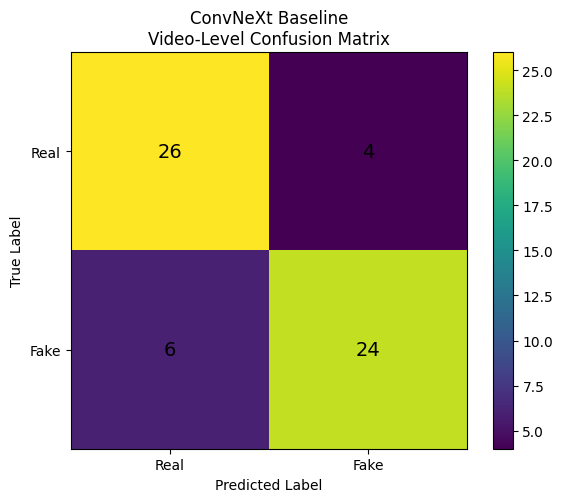


Channel Attention

Classification Report:
              precision    recall  f1-score   support

        Real     0.7027    0.8667    0.7761        30
        Fake     0.8261    0.6333    0.7170        30

    accuracy                         0.7500        60
   macro avg     0.7644    0.7500    0.7466        60
weighted avg     0.7644    0.7500    0.7466        60

Confusion Matrix:
[[26  4]
 [11 19]]

Error breakdown:
True Negatives  (TN): 26
False Positives (FP): 4
False Negatives (FN): 11
True Positives  (TP): 19


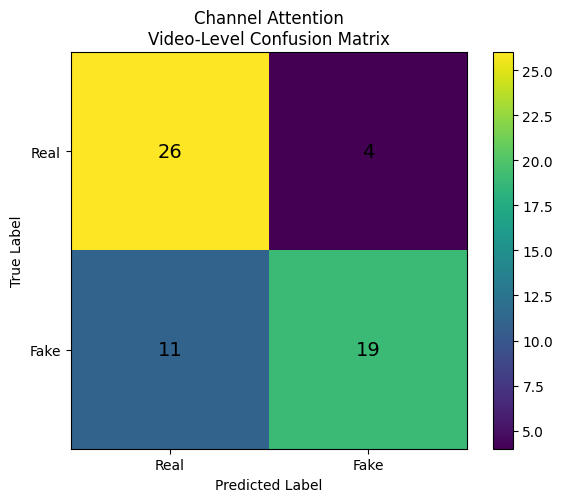


Spatial Attention

Classification Report:
              precision    recall  f1-score   support

        Real     0.8065    0.8333    0.8197        30
        Fake     0.8276    0.8000    0.8136        30

    accuracy                         0.8167        60
   macro avg     0.8170    0.8167    0.8166        60
weighted avg     0.8170    0.8167    0.8166        60

Confusion Matrix:
[[25  5]
 [ 6 24]]

Error breakdown:
True Negatives  (TN): 25
False Positives (FP): 5
False Negatives (FN): 6
True Positives  (TP): 24


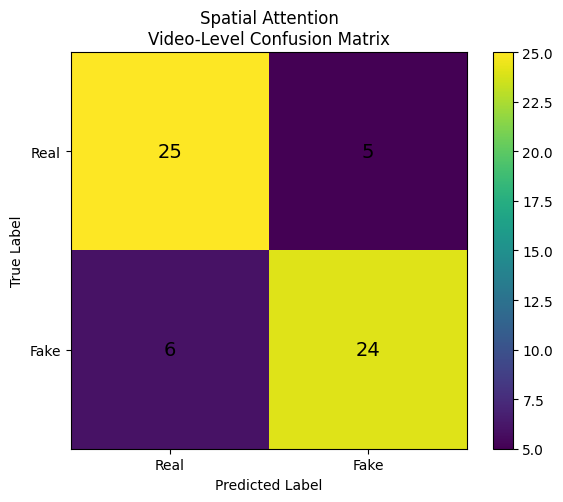


ConvNeXt + FFAM

Classification Report:
              precision    recall  f1-score   support

        Real     0.8333    0.8333    0.8333        30
        Fake     0.8333    0.8333    0.8333        30

    accuracy                         0.8333        60
   macro avg     0.8333    0.8333    0.8333        60
weighted avg     0.8333    0.8333    0.8333        60

Confusion Matrix:
[[25  5]
 [ 5 25]]

Error breakdown:
True Negatives  (TN): 25
False Positives (FP): 5
False Negatives (FN): 5
True Positives  (TP): 25


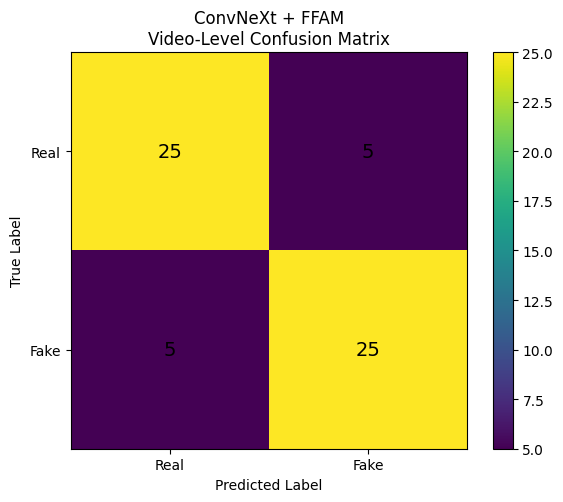


CLASSIFICATION REPORTS COMPLETE


In [63]:
# ============================================================
# CELL 56 — CLASSIFICATION REPORTS + CONFUSION MATRICES
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("VIDEO-LEVEL CLASSIFICATION REPORTS")
print("=" * 70)


for model_name, result in test_results.items():

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    video_predictions = (
        result["video_predictions"]
    )

    # --------------------------------------------------------
    # Video-level ground truth and probability
    # --------------------------------------------------------

    y_true_video = (
        video_predictions["label"]
        .values
    )

    y_prob_video = (
        video_predictions["probability"]
        .values
    )

    # --------------------------------------------------------
    # Classification threshold
    # --------------------------------------------------------

    y_pred_video = (
        y_prob_video >= 0.5
    ).astype(int)

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------

    print("\nClassification Report:")

    print(
        classification_report(
            y_true_video,
            y_pred_video,
            labels=[0, 1],
            target_names=[
                "Real",
                "Fake"
            ],
            digits=4,
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true_video,
        y_pred_video,
        labels=[0, 1]
    )

    print("Confusion Matrix:")
    print(cm)

    # --------------------------------------------------------
    # Explicit TP / TN / FP / FN
    # --------------------------------------------------------

    tn, fp, fn, tp = cm.ravel()

    print("\nError breakdown:")
    print("True Negatives  (TN):", tn)
    print("False Positives (FP):", fp)
    print("False Negatives (FN):", fn)
    print("True Positives  (TP):", tp)

    # --------------------------------------------------------
    # Plot confusion matrix
    # --------------------------------------------------------

    plt.figure(
        figsize=(6, 5)
    )

    plt.imshow(
        cm,
        interpolation="nearest"
    )

    plt.title(
        f"{model_name}\nVideo-Level Confusion Matrix"
    )

    plt.colorbar()

    plt.xticks(
        [0, 1],
        ["Real", "Fake"]
    )

    plt.yticks(
        [0, 1],
        ["Real", "Fake"]
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    # --------------------------------------------------------
    # Add values inside cells
    # --------------------------------------------------------

    for i in range(2):

        for j in range(2):

            plt.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=14
            )

    plt.tight_layout()

    # Safe filename
    safe_name = (
        model_name
        .lower()
        .replace(" ", "_")
        .replace("+", "plus")
    )

    plt.savefig(
        f"/kaggle/working/{safe_name}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


print("\n" + "=" * 70)
print("CLASSIFICATION REPORTS COMPLETE")
print("=" * 70)

## 17. Final Results and Interpretation

The final comparison is performed at the video level. The four configurations are evaluated under the same frozen dataset split and evaluation procedure.

The ablation is interpreted comparatively rather than by accuracy alone. ROC-AUC and PR-AUC are reported alongside threshold-based metrics, and bootstrap confidence intervals are provided to quantify uncertainty on the 60-video test set.

The key scientific question is whether attention helps consistently and whether combining attention mechanisms provides an additional advantage. A variant that performs worse than the baseline is retained as a meaningful ablation result rather than being omitted.

In [64]:
# ============================================================
# CELL 57 — VIDEO-LEVEL BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================

import numpy as np
import pandas as pd

def bootstrap_metric_ci(
    y_true,
    y_prob,
    metric_name,
    n_bootstrap=2000,
    seed=SEED
):
    """
    Calculate percentile bootstrap 95% CI
    at the VIDEO level.
    """

    rng = np.random.default_rng(seed)

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    n = len(y_true)

    bootstrap_scores = []

    for _ in range(n_bootstrap):

        indices = rng.integers(
            0,
            n,
            size=n
        )

        boot_true = y_true[indices]
        boot_prob = y_prob[indices]

        # ROC-AUC / PR-AUC require both classes
        if len(np.unique(boot_true)) < 2:
            continue

        if metric_name == "accuracy":

            score = accuracy_score(
                boot_true,
                (boot_prob >= 0.5).astype(int)
            )

        elif metric_name == "balanced_accuracy":

            score = balanced_accuracy_score(
                boot_true,
                (boot_prob >= 0.5).astype(int)
            )

        elif metric_name == "precision":

            score = precision_score(
                boot_true,
                (boot_prob >= 0.5).astype(int),
                zero_division=0
            )

        elif metric_name == "recall":

            score = recall_score(
                boot_true,
                (boot_prob >= 0.5).astype(int),
                zero_division=0
            )

        elif metric_name == "f1":

            score = f1_score(
                boot_true,
                (boot_prob >= 0.5).astype(int),
                zero_division=0
            )

        elif metric_name == "roc_auc":

            score = roc_auc_score(
                boot_true,
                boot_prob
            )

        elif metric_name == "pr_auc":

            score = average_precision_score(
                boot_true,
                boot_prob
            )

        else:
            raise ValueError(
                f"Unknown metric: {metric_name}"
            )

        bootstrap_scores.append(score)

    bootstrap_scores = np.asarray(
        bootstrap_scores
    )

    lower = np.percentile(
        bootstrap_scores,
        2.5
    )

    upper = np.percentile(
        bootstrap_scores,
        97.5
    )

    return lower, upper


# ------------------------------------------------------------
# Calculate CIs for every model
# ------------------------------------------------------------

bootstrap_results = []

metrics_for_ci = [
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc"
]

for model_name, result in test_results.items():

    video_predictions = (
        result["video_predictions"]
    )

    y_true = (
        video_predictions["label"].values
    )

    y_prob = (
        video_predictions["probability"].values
    )

    row = {
        "Model": model_name
    }

    for metric in metrics_for_ci:

        lower, upper = bootstrap_metric_ci(
            y_true,
            y_prob,
            metric,
            n_bootstrap=2000,
            seed=SEED
        )

        row[f"{metric}_lower"] = lower
        row[f"{metric}_upper"] = upper

    bootstrap_results.append(row)


bootstrap_ci_table = pd.DataFrame(
    bootstrap_results
)

print("=" * 80)
print("VIDEO-LEVEL BOOTSTRAP 95% CONFIDENCE INTERVALS")
print("=" * 80)

display(
    bootstrap_ci_table
)

VIDEO-LEVEL BOOTSTRAP 95% CONFIDENCE INTERVALS


,Model,accuracy_lower,accuracy_upper,balanced_accuracy_lower,balanced_accuracy_upper,precision_lower,precision_upper,recall_lower,recall_upper,f1_lower,f1_upper,roc_auc_lower,roc_auc_upper,pr_auc_lower,pr_auc_upper
0,ConvNeXt Baseline,0.733333,0.916667,0.731491,0.918270,0.718750,0.967742,0.642857,0.931034,0.708333,0.923077,0.681139,0.935270,0.693393,0.953218
1,Channel Attention,0.633333,0.850000,0.639830,0.850000,0.655172,0.961538,0.448276,0.793103,0.560000,0.836364,0.680122,0.925942,0.659183,0.945249
2,Spatial Attention,0.716667,0.900417,0.713534,0.908389,0.680000,0.960000,0.642857,0.931034,0.690878,0.911765,0.709315,0.941264,0.688777,0.956219
3,ConvNeXt + FFAM,0.733333,0.916667,0.733333,0.919674,0.700000,0.961538,0.687500,0.962996,0.724034,0.925926,0.698225,0.943286,0.690531,0.959612


In [65]:
# ============================================================
# CELL 58 — FINAL RESEARCH RESULTS TABLE
# ============================================================

final_results_rows = []

for model_name, result in test_results.items():

    metrics = result["video_metrics"]

    ci_row = bootstrap_ci_table[
        bootstrap_ci_table["Model"] == model_name
    ].iloc[0]

    final_results_rows.append({

        "Model": model_name,

        "Accuracy":
            metrics["accuracy"],

        "Balanced Accuracy":
            metrics["balanced_accuracy"],

        "Precision":
            metrics["precision"],

        "Recall":
            metrics["recall"],

        "F1":
            metrics["f1"],

        "ROC-AUC":
            metrics["roc_auc"],

        "ROC-AUC 95% CI":
            f"{ci_row['roc_auc_lower']:.4f} – "
            f"{ci_row['roc_auc_upper']:.4f}",

        "PR-AUC":
            metrics["pr_auc"],

        "PR-AUC 95% CI":
            f"{ci_row['pr_auc_lower']:.4f} – "
            f"{ci_row['pr_auc_upper']:.4f}"
    })


final_results_table = pd.DataFrame(
    final_results_rows
)

final_results_table = (
    final_results_table
    .sort_values(
        "ROC-AUC",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 100)
print("FINAL VIDEO-LEVEL RESEARCH RESULTS")
print("=" * 100)

display(final_results_table)

FINAL VIDEO-LEVEL RESEARCH RESULTS


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC 95% CI,PR-AUC,PR-AUC 95% CI
0,Spatial Attention,0.816667,0.816667,0.827586,0.800000,0.813559,0.833333,0.7093 – 0.9413,0.833610,0.6888 – 0.9562
1,ConvNeXt + FFAM,0.833333,0.833333,0.833333,0.833333,0.833333,0.830000,0.6982 – 0.9433,0.836563,0.6905 – 0.9596
2,ConvNeXt Baseline,0.833333,0.833333,0.857143,0.800000,0.827586,0.817778,0.6811 – 0.9353,0.831127,0.6934 – 0.9532
3,Channel Attention,0.750000,0.750000,0.826087,0.633333,0.716981,0.814444,0.6801 – 0.9259,0.808012,0.6592 – 0.9452


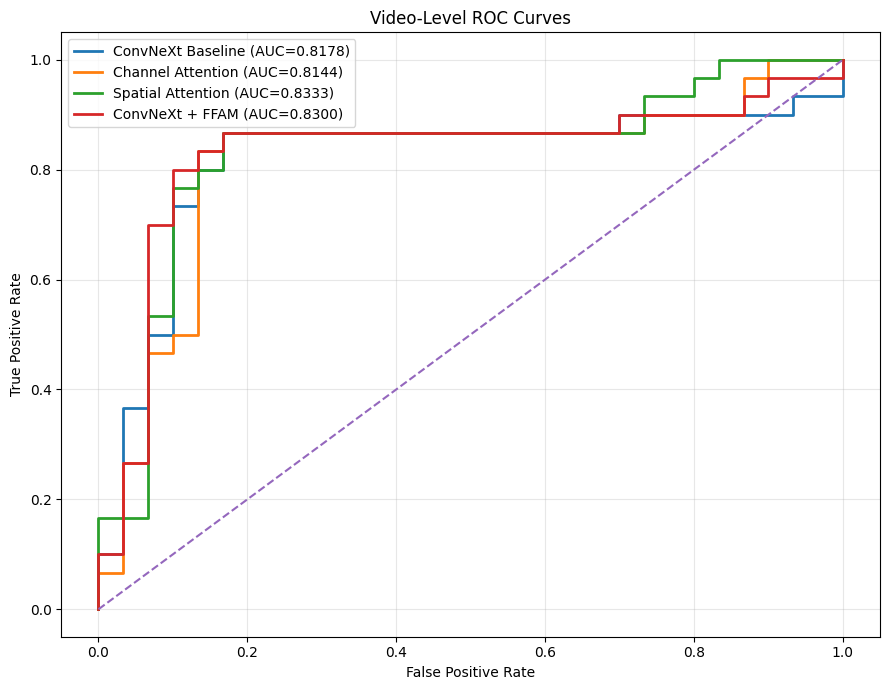

In [66]:
# ============================================================
# CELL 59 — VIDEO-LEVEL ROC CURVES
# ============================================================

plt.figure(
    figsize=(9, 7)
)

for model_name, result in test_results.items():

    video_predictions = (
        result["video_predictions"]
    )

    y_true = (
        video_predictions["label"].values
    )

    y_prob = (
        video_predictions["probability"].values
    )

    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC={auc:.4f})"
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Video-Level ROC Curves"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

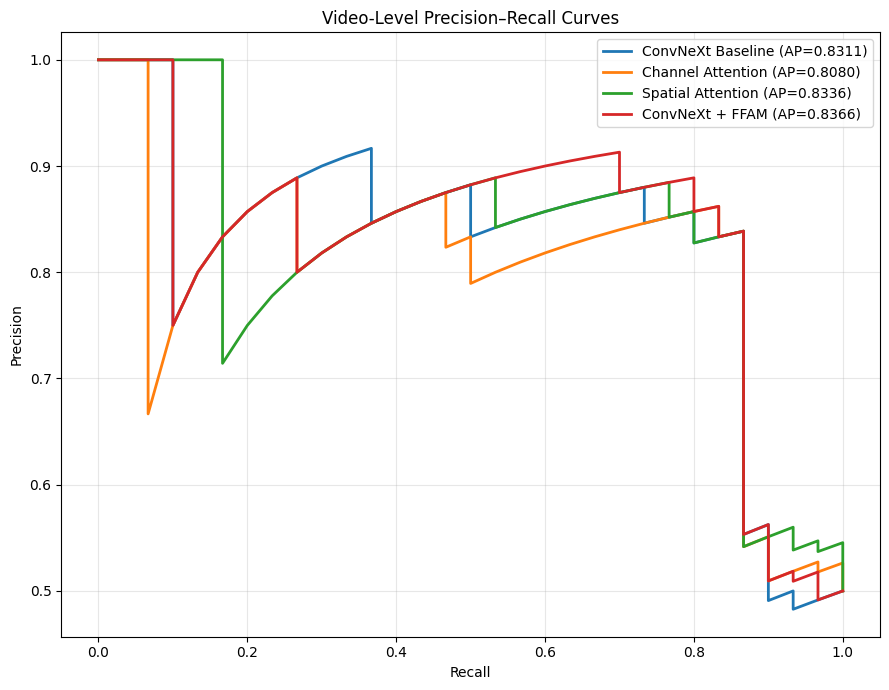

In [67]:
# ============================================================
# CELL 60 — VIDEO-LEVEL PRECISION-RECALL CURVES
# ============================================================

plt.figure(
    figsize=(9, 7)
)

for model_name, result in test_results.items():

    video_predictions = (
        result["video_predictions"]
    )

    y_true = (
        video_predictions["label"].values
    )

    y_prob = (
        video_predictions["probability"].values
    )

    precision, recall, _ = (
        precision_recall_curve(
            y_true,
            y_prob
        )
    )

    pr_auc = average_precision_score(
        y_true,
        y_prob
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{model_name} (AP={pr_auc:.4f})"
    )


plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Video-Level Precision–Recall Curves"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [68]:
# ============================================================
# CELL 61 — MODEL PERFORMANCE COMPARISON
# ============================================================

comparison_metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

comparison_df = (
    final_results_table[
        ["Model"] + comparison_metrics
    ]
    .copy()
)

display(
    comparison_df
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Spatial Attention,0.816667,0.816667,0.827586,0.800000,0.813559,0.833333,0.833610
1,ConvNeXt + FFAM,0.833333,0.833333,0.833333,0.833333,0.833333,0.830000,0.836563
2,ConvNeXt Baseline,0.833333,0.833333,0.857143,0.800000,0.827586,0.817778,0.831127
3,Channel Attention,0.750000,0.750000,0.826087,0.633333,0.716981,0.814444,0.808012


In [69]:
# ============================================================
# CELL 62 — ATTENTION ABLATION IMPROVEMENT OVER BASELINE
# ============================================================

baseline_name = "ConvNeXt Baseline"

baseline_row = (
    final_results_table[
        final_results_table["Model"] == baseline_name
    ]
    .iloc[0]
)

ablation_models = [
    "Channel Attention",
    "Spatial Attention",
    "ConvNeXt + FFAM"
]

improvement_rows = []

for model_name in ablation_models:

    model_row = (
        final_results_table[
            final_results_table["Model"] == model_name
        ]
        .iloc[0]
    )

    for metric in comparison_metrics:

        baseline_value = baseline_row[metric]
        model_value = model_row[metric]

        improvement_rows.append({

            "Variant":
                model_name,

            "Metric":
                metric,

            "Baseline":
                baseline_value,

            "Variant Value":
                model_value,

            "Absolute Improvement":
                model_value - baseline_value
        })


attention_ablation_improvement_table = pd.DataFrame(
    improvement_rows
)

print("=" * 90)
print("ATTENTION ABLATION: IMPROVEMENT OVER CONVNEXT BASELINE")
print("=" * 90)

display(
    attention_ablation_improvement_table
)

ATTENTION ABLATION: IMPROVEMENT OVER CONVNEXT BASELINE


,Variant,Metric,Baseline,Variant Value,Absolute Improvement
0,Channel Attention,Accuracy,0.833333,0.750000,-0.083333
1,Channel Attention,Balanced Accuracy,0.833333,0.750000,-0.083333
2,Channel Attention,Precision,0.857143,0.826087,-0.031056
3,Channel Attention,Recall,0.800000,0.633333,-0.166667
4,Channel Attention,F1,0.827586,0.716981,-0.110605
5,Channel Attention,ROC-AUC,0.817778,0.814444,-0.003333
6,Channel Attention,PR-AUC,0.831127,0.808012,-0.023115
7,Spatial Attention,Accuracy,0.833333,0.816667,-0.016667
8,Spatial Attention,Balanced Accuracy,0.833333,0.816667,-0.016667
9,Spatial Attention,Precision,0.857143,0.827586,-0.029557


In [70]:
# ============================================================
# CELL 63 — VIDEO-LEVEL ERROR ANALYSIS
# ============================================================

error_analysis = {}

for model_name, result in test_results.items():

    video_predictions = (
        result["video_predictions"]
        .copy()
    )

    video_predictions["prediction"] = (
        video_predictions["probability"] >= 0.5
    ).astype(int)

    video_predictions["correct"] = (
        video_predictions["label"]
        ==
        video_predictions["prediction"]
    )

    video_predictions["confidence"] = (
        np.abs(
            video_predictions["probability"]
            - 0.5
        )
        * 2
    )

    errors = (
        video_predictions[
            video_predictions["correct"] == False
        ]
        .sort_values(
            "confidence",
            ascending=True
        )
        .reset_index(drop=True)
    )

    error_analysis[model_name] = errors

    print("\n" + "=" * 80)
    print(model_name)
    print("=" * 80)

    print(
        "Total test videos:",
        len(video_predictions)
    )

    print(
        "Incorrect videos:",
        len(errors)
    )

    print(
        "Error rate:",
        len(errors) / len(video_predictions)
    )

    display(
        errors.head(20)
    )


ConvNeXt Baseline
Total test videos: 60
Incorrect videos: 10
Error rate: 0.16666666666666666


,video_name,label,probability,num_frames,prediction,correct,confidence
0,07_26__walk_down_hall_angry__FGNGC2GT.mp4,1,0.442017,10,0,False,0.115967
1,01__walking_down_street_outside_angry.mp4,0,0.581339,10,1,False,0.162677
2,03_27__walking_down_indoor_hall_disgust__IL675...,1,0.365771,10,0,False,0.268457
3,06__kitchen_still.mp4,0,0.686719,10,1,False,0.373438
4,07__secret_conversation.mp4,0,0.831543,10,1,False,0.663086
5,10_22__kitchen_pan__EHARPYBT.mp4,1,0.067805,10,0,False,0.864389
6,02__meeting_serious.mp4,0,0.948438,10,1,False,0.896875
7,09_20__talking_angry_couch__0IRM5ADD.mp4,1,0.047400,10,0,False,0.905200
8,10_22__kitchen_still__EHARPYBT.mp4,1,0.043571,10,0,False,0.912857
9,10_19__kitchen_still__IDX76N5R.mp4,1,0.042393,10,0,False,0.915213



Channel Attention
Total test videos: 60
Incorrect videos: 15
Error rate: 0.25


,video_name,label,probability,num_frames,prediction,correct,confidence
0,07_26__walking_down_street_outside_angry__FGNG...,1,0.480737,10,0,False,0.038525
1,06_25__walking_and_outside_surprised__MI9BDQ7M...,1,0.471094,10,0,False,0.057813
2,05_17__hugging_happy__YTJYYDO9.mp4,1,0.454028,10,0,False,0.091943
3,03_04__talking_angry_couch__T04P6ELC.mp4,1,0.423083,10,0,False,0.153833
4,01__walking_down_street_outside_angry.mp4,0,0.580411,10,1,False,0.160822
5,02_03__walking_down_street_outside_angry__QH3Y...,1,0.367072,10,0,False,0.265857
6,03_27__walking_down_indoor_hall_disgust__IL675...,1,0.348730,10,0,False,0.302539
7,07_26__walk_down_hall_angry__FGNGC2GT.mp4,1,0.325195,10,0,False,0.349609
8,06__kitchen_still.mp4,0,0.679590,10,1,False,0.359180
9,07__secret_conversation.mp4,0,0.792822,10,1,False,0.585644



Spatial Attention
Total test videos: 60
Incorrect videos: 11
Error rate: 0.18333333333333332


,video_name,label,probability,num_frames,prediction,correct,confidence
0,07_26__walk_down_hall_angry__FGNGC2GT.mp4,1,0.456335,10,0,False,0.087329
1,03_27__walking_down_indoor_hall_disgust__IL675...,1,0.448022,10,0,False,0.103955
2,01__hugging_happy.mp4,0,0.552423,10,1,False,0.104846
3,01__walking_down_street_outside_angry.mp4,0,0.589886,10,1,False,0.179773
4,06__kitchen_still.mp4,0,0.727734,10,1,False,0.455469
5,10_22__kitchen_pan__EHARPYBT.mp4,1,0.112738,10,0,False,0.774524
6,09_20__talking_angry_couch__0IRM5ADD.mp4,1,0.107092,10,0,False,0.785815
7,07__secret_conversation.mp4,0,0.897803,10,1,False,0.795605
8,10_22__kitchen_still__EHARPYBT.mp4,1,0.084207,10,0,False,0.831586
9,10_19__kitchen_still__IDX76N5R.mp4,1,0.079346,10,0,False,0.841309



ConvNeXt + FFAM
Total test videos: 60
Incorrect videos: 10
Error rate: 0.16666666666666666


,video_name,label,probability,num_frames,prediction,correct,confidence
0,01__hugging_happy.mp4,0,0.520764,10,1,False,0.041528
1,03_27__walking_down_indoor_hall_disgust__IL675...,1,0.477734,10,0,False,0.044531
2,01__walking_down_street_outside_angry.mp4,0,0.574088,10,1,False,0.148175
3,06__kitchen_still.mp4,0,0.653711,10,1,False,0.307422
4,07__secret_conversation.mp4,0,0.856494,10,1,False,0.712988
5,10_22__kitchen_pan__EHARPYBT.mp4,1,0.095200,10,0,False,0.809601
6,09_20__talking_angry_couch__0IRM5ADD.mp4,1,0.060928,10,0,False,0.878143
7,02__meeting_serious.mp4,0,0.944043,10,1,False,0.888086
8,10_19__kitchen_still__IDX76N5R.mp4,1,0.041625,10,0,False,0.916750
9,10_22__kitchen_still__EHARPYBT.mp4,1,0.038223,10,0,False,0.923555


In [71]:
# ============================================================
# CELL 64 — BEST-MODEL FALSE POSITIVE / FALSE NEGATIVE ANALYSIS
# ============================================================

best_model_name = (
    final_results_table
    .sort_values("ROC-AUC", ascending=False)
    .iloc[0]["Model"]
)

best_model_predictions = (
    test_results[best_model_name]
    ["video_predictions"]
    .copy()
)

best_model_predictions["prediction"] = (
    best_model_predictions["probability"] >= 0.5
).astype(int)


false_positives = (
    best_model_predictions[
        (best_model_predictions["label"] == 0) &
        (best_model_predictions["prediction"] == 1)
    ]
    .sort_values(
        "probability",
        ascending=False
    )
    .reset_index(drop=True)
)


false_negatives = (
    best_model_predictions[
        (best_model_predictions["label"] == 1) &
        (best_model_predictions["prediction"] == 0)
    ]
    .sort_values(
        "probability",
        ascending=True
    )
    .reset_index(drop=True)
)


print("=" * 80)
print(f"{best_model_name} FALSE POSITIVES")
print("=" * 80)

print(
    "Number of false positives:",
    len(false_positives)
)

display(
    false_positives
)


print("\n" + "=" * 80)
print(f"{best_model_name} FALSE NEGATIVES")
print("=" * 80)

print(
    "Number of false negatives:",
    len(false_negatives)
)

display(
    false_negatives
)

Spatial Attention FALSE POSITIVES
Number of false positives: 5


,video_name,label,probability,num_frames,prediction
0,02__meeting_serious.mp4,0,0.933350,10,1
1,07__secret_conversation.mp4,0,0.897803,10,1
2,06__kitchen_still.mp4,0,0.727734,10,1
3,01__walking_down_street_outside_angry.mp4,0,0.589886,10,1
4,01__hugging_happy.mp4,0,0.552423,10,1



Spatial Attention FALSE NEGATIVES
Number of false negatives: 6


,video_name,label,probability,num_frames,prediction
0,10_19__kitchen_still__IDX76N5R.mp4,1,0.079346,10,0
1,10_22__kitchen_still__EHARPYBT.mp4,1,0.084207,10,0
2,09_20__talking_angry_couch__0IRM5ADD.mp4,1,0.107092,10,0
3,10_22__kitchen_pan__EHARPYBT.mp4,1,0.112738,10,0
4,03_27__walking_down_indoor_hall_disgust__IL675...,1,0.448022,10,0
5,07_26__walk_down_hall_angry__FGNGC2GT.mp4,1,0.456335,10,0


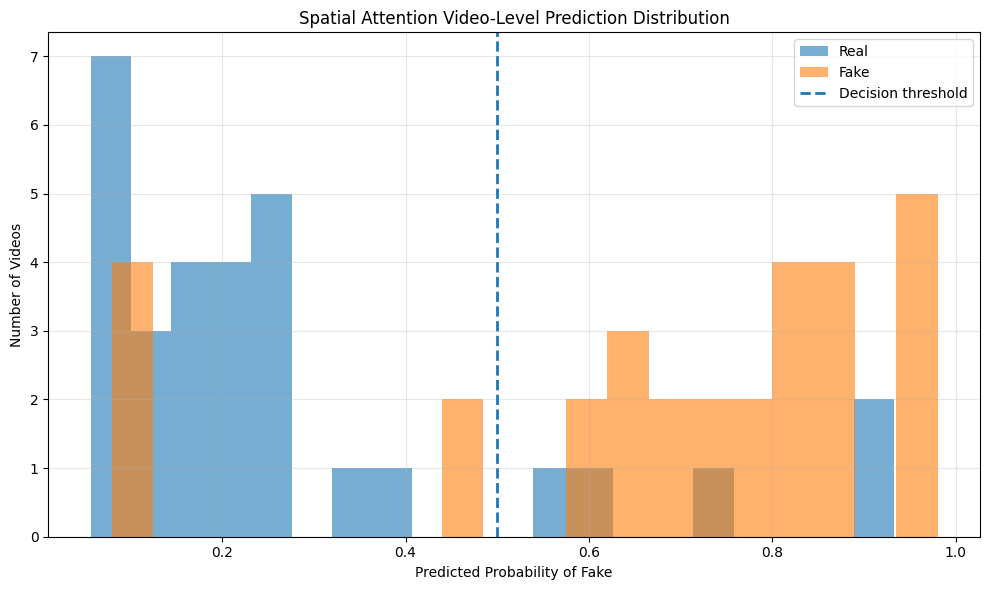

In [72]:
# ============================================================
# CELL 65 — BEST-MODEL PREDICTION DISTRIBUTION
# ============================================================

best_model_name = (
    final_results_table
    .sort_values("ROC-AUC", ascending=False)
    .iloc[0]["Model"]
)

best_model_predictions = (
    test_results[best_model_name]
    ["video_predictions"]
)

real_probabilities = (
    best_model_predictions[
        best_model_predictions["label"] == 0
    ]["probability"]
)

fake_probabilities = (
    best_model_predictions[
        best_model_predictions["label"] == 1
    ]["probability"]
)


plt.figure(
    figsize=(10, 6)
)

plt.hist(
    real_probabilities,
    bins=20,
    alpha=0.6,
    label="Real"
)

plt.hist(
    fake_probabilities,
    bins=20,
    alpha=0.6,
    label="Fake"
)

plt.axvline(
    0.5,
    linestyle="--",
    linewidth=2,
    label="Decision threshold"
)

plt.xlabel(
    "Predicted Probability of Fake"
)

plt.ylabel(
    "Number of Videos"
)

plt.title(
    f"{best_model_name} Video-Level Prediction Distribution"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [73]:
# ============================================================
# CELL 66 — SAVE VIDEO-LEVEL PREDICTIONS
# ============================================================

RESULT_DIR = "/kaggle/working/research_results"

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)


for model_name, result in test_results.items():

    safe_name = (
        model_name
        .lower()
        .replace(" ", "_")
        .replace("+", "plus")
    )

    prediction_path = os.path.join(
        RESULT_DIR,
        f"{safe_name}_video_predictions.csv"
    )

    result["video_predictions"].to_csv(
        prediction_path,
        index=False
    )

    print(
        "Saved:",
        prediction_path
    )

Saved: /kaggle/working/research_results/convnext_baseline_video_predictions.csv
Saved: /kaggle/working/research_results/channel_attention_video_predictions.csv
Saved: /kaggle/working/research_results/spatial_attention_video_predictions.csv
Saved: /kaggle/working/research_results/convnext_plus_ffam_video_predictions.csv


In [75]:
# ============================================================
# CELL 66 — GRAD-CAM IMPLEMENTATION
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


class GradCAM:

    def __init__(
        self,
        model,
        target_layer
    ):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = (
            target_layer.register_forward_hook(
                self._forward_hook
            )
        )

        self.backward_handle = (
            target_layer.register_full_backward_hook(
                self._backward_hook
            )
        )


    def _forward_hook(
        self,
        module,
        input,
        output
    ):

        self.activations = output


    def _backward_hook(
        self,
        module,
        grad_input,
        grad_output
    ):

        self.gradients = (
            grad_output[0]
        )


    def generate(
        self,
        input_tensor,
        target_class=None
    ):

        self.model.eval()

        self.model.zero_grad()

        output = self.model(
            input_tensor
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )


        # ----------------------------------------------------
        # If target class is not specified,
        # explain the model's predicted class.
        # ----------------------------------------------------

        if target_class is None:

            target_class = int(
                torch.argmax(
                    probabilities,
                    dim=1
                ).item()
            )


        target_score = output[
            0,
            target_class
        ]


        target_score.backward()


        # ----------------------------------------------------
        # Feature activations
        # ----------------------------------------------------

        activations = (
            self.activations
        )


        gradients = (
            self.gradients
        )


        # ----------------------------------------------------
        # Global-average gradient weights
        # ----------------------------------------------------

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )


        # ----------------------------------------------------
        # Weighted feature maps
        # ----------------------------------------------------

        cam = (
            weights * activations
        ).sum(
            dim=1,
            keepdim=True
        )


        cam = F.relu(
            cam
        )


        # ----------------------------------------------------
        # Resize to input image size
        # ----------------------------------------------------

        cam = F.interpolate(
            cam,
            size=(
                input_tensor.shape[2],
                input_tensor.shape[3]
            ),
            mode="bilinear",
            align_corners=False
        )


        cam = cam[0, 0].detach().cpu().numpy()


        # ----------------------------------------------------
        # Normalize CAM
        # ----------------------------------------------------

        cam_min = cam.min()
        cam_max = cam.max()

        if cam_max - cam_min > 1e-8:

            cam = (
                cam - cam_min
            ) / (
                cam_max - cam_min
            )

        else:

            cam = np.zeros_like(
                cam
            )


        return (
            cam,
            probabilities[0]
            .detach()
            .cpu()
            .numpy(),
            target_class
        )


    def remove_hooks(self):

        self.forward_handle.remove()

        self.backward_handle.remove()

In [76]:
# ============================================================
# CELL 67 — PREPARE BEST MODEL FOR GRAD-CAM
# ============================================================

print("=" * 80)
print("PREPARING BEST MODEL FOR GRAD-CAM")
print("=" * 80)


# ------------------------------------------------------------
# Get the empirically best-performing model
# ------------------------------------------------------------

best_model_name = (
    final_results_table
    .sort_values("ROC-AUC", ascending=False)
    .iloc[0]["Model"]
)

best_model = model_results[
    best_model_name
]["model"]


best_model = best_model.to(
    DEVICE
)


best_model.eval()


# ------------------------------------------------------------
# Target the final ConvNeXt feature stage
# ------------------------------------------------------------

target_layer = (
    best_model
    .backbone
    .features[-1]
)


print(
    "Target layer:",
    target_layer
)


gradcam = GradCAM(
    model=best_model,
    target_layer=target_layer
)


print("\nGrad-CAM is ready.")

PREPARING BEST MODEL FOR GRAD-CAM
Target layer: Sequential(
  (0): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=768, out_features=3072, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=3072, out_features=768, bias=True)
      (6): Permute()
    )
    (stochastic_depth): StochasticDepth(p=0.08823529411764706, mode=row)
  )
  (1): CNBlock(
    (block): Sequential(
      (0): Conv2d(768, 768, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=768)
      (1): Permute()
      (2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (3): Linear(in_features=768, out_features=3072, bias=True)
      (4): GELU(approximate='none')
      (5): Linear(in_features=3072, out_features=768, bias=True)
      (6): Permute()
    )
    (stochastic_depth): StochasticDepth(p

In [77]:
# ============================================================
# CELL 67 — SAVE RESEARCH RESULT TABLES
# ============================================================

final_results_table.to_csv(
    os.path.join(
        RESULT_DIR,
        "final_video_level_results.csv"
    ),
    index=False
)

bootstrap_ci_table.to_csv(
    os.path.join(
        RESULT_DIR,
        "bootstrap_95CI_results.csv"
    ),
    index=False
)

attention_ablation_improvement_table.to_csv(
    os.path.join(
        RESULT_DIR,
        "attention_ablation_vs_baseline_improvement.csv"
    ),
    index=False
)

comparison_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "model_comparison.csv"
    ),
    index=False
)

print("=" * 70)
print("RESULT FILES SAVED")
print("=" * 70)

for filename in sorted(
    os.listdir(RESULT_DIR)
):

    print(filename)

RESULT FILES SAVED
attention_ablation_vs_baseline_improvement.csv
bootstrap_95CI_results.csv
channel_attention_video_predictions.csv
convnext_baseline_video_predictions.csv
convnext_plus_ffam_video_predictions.csv
final_video_level_results.csv
model_comparison.csv
spatial_attention_video_predictions.csv


In [78]:
# ============================================================
# FINAL EXPERIMENT SUMMARY
# ============================================================

# Always derive the reported split sizes from the frozen final
# manifest rather than legacy variables from the exploratory split.

final_manifest = pd.read_csv(
    MANIFEST_PATH
)

train_videos = (
    final_manifest[
        final_manifest["split"] == "train"
    ]["video_name"]
    .nunique()
)

validation_videos = (
    final_manifest[
        final_manifest["split"] == "val"
    ]["video_name"]
    .nunique()
)

test_videos = (
    final_manifest[
        final_manifest["split"] == "test"
    ]["video_name"]
    .nunique()
)

# Identify the strongest evaluated variant using validation-independent
# final test ROC-AUC. This is a reporting step only; model selection
# itself was already performed using validation ROC-AUC.

best_model_name = (
    final_results_table
    .sort_values("ROC-AUC", ascending=False)
    .iloc[0]["Model"]
)

best_model_row = (
    final_results_table[
        final_results_table["Model"] == best_model_name
    ]
    .iloc[0]
)

experiment_summary = {

    "project":
        "Deepfake Detection with ConvNeXt-Tiny: An Attention Ablation Study",

    "dataset":
        "FaceForensics++",

    "total_videos":
        int(final_manifest["video_name"].nunique()),

    "real_videos":
        int((final_manifest["label"] == 0).sum()),

    "fake_videos":
        int((final_manifest["label"] == 1).sum()),

    "frames_per_video":
        10,

    "total_frames":
        4000,

    "train_videos":
        int(train_videos),

    "validation_videos":
        int(validation_videos),

    "test_videos":
        int(test_videos),

    "models_evaluated":
        list(model_results.keys()),

    "primary_evaluation_level":
        "Video",

    "video_probability_aggregation":
        "Mean frame-level fake probability",

    "model_selection_metric":
        "Validation ROC-AUC",

    "final_best_model_by_test_roc_auc":
        str(best_model_name),

    "best_model_test_accuracy":
        float(best_model_row["Accuracy"]),

    "best_model_test_f1":
        float(best_model_row["F1"]),

    "best_model_test_roc_auc":
        float(best_model_row["ROC-AUC"]),

    "best_model_test_pr_auc":
        float(best_model_row["PR-AUC"]),

    "split_protocol":
        "Deterministic video-level split with manipulation-pair exclusivity for fake videos",

    "generalization_scope":
        "Held-out manipulation pairs; not strict identity-independent evaluation",

    "bootstrap_iterations":
        2000,

    "confidence_interval":
        "95%",

    "random_seed":
        int(SEED)
}

summary_path = os.path.join(
    RESULT_DIR,
    "experiment_summary.json"
)

with open(
    summary_path,
    "w"
) as f:

    json.dump(
        experiment_summary,
        f,
        indent=4
    )

print("=" * 80)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 80)

for key, value in experiment_summary.items():

    print(
        f"{key}: {value}"
    )

assert train_videos == 280
assert validation_videos == 60
assert test_videos == 60

print("\n✓ FINAL SPLIT VERIFIED: 280 / 60 / 60")
print("\nExperiment summary saved to:")
print(summary_path)

FINAL EXPERIMENT SUMMARY
project: Deepfake Detection with ConvNeXt-Tiny: An Attention Ablation Study
dataset: FaceForensics++
total_videos: 400
real_videos: 200
fake_videos: 200
frames_per_video: 10
total_frames: 4000
train_videos: 280
validation_videos: 60
test_videos: 60
models_evaluated: ['ConvNeXt Baseline', 'Channel Attention', 'Spatial Attention', 'ConvNeXt + FFAM']
primary_evaluation_level: Video
video_probability_aggregation: Mean frame-level fake probability
model_selection_metric: Validation ROC-AUC
final_best_model_by_test_roc_auc: Spatial Attention
best_model_test_accuracy: 0.8166666666666667
best_model_test_f1: 0.8135593220338984
best_model_test_roc_auc: 0.8333333333333334
best_model_test_pr_auc: 0.8336096194980559
split_protocol: Deterministic video-level split with manipulation-pair exclusivity for fake videos
generalization_scope: Held-out manipulation pairs; not strict identity-independent evaluation
bootstrap_iterations: 2000
confidence_interval: 95%
random_seed: 42



In [82]:

# ============================================================
# CREATE SEPARATE DOWNLOADABLE FILES FOR YOUR GITHUB PROJECT
# ============================================================

from pathlib import Path
import zipfile

WORKING = Path("/kaggle/working")
OUTPUTS = WORKING / "github_outputs"

def create_download_zip(folder, zip_name):
    folder = Path(folder)
    zip_path = WORKING / zip_name

    if not folder.is_dir():
        print(f"NOT FOUND: {folder}")
        return

    files = [p for p in folder.rglob("*") if p.is_file()]

    if not files:
        print(f"EMPTY FOLDER: {folder}")
        return

    with zipfile.ZipFile(
        zip_path, "w", compression=zipfile.ZIP_STORED
    ) as archive:
        for file in files:
            archive.write(file, file.relative_to(folder))

    size_mb = zip_path.stat().st_size / (1024 * 1024)
    print(f"READY TO DOWNLOAD: {zip_path.name} ({size_mb:.2f} MB)")

# 1. Figures — your 7 saved plots
create_download_zip(
    OUTPUTS / "figures",
    "deepfake_figures.zip"
)

# 2. Results — metrics, predictions and training histories
create_download_zip(
    OUTPUTS / "results",
    "deepfake_results.zip"
)

# 3. Model and face-detector checkpoints, if present
create_download_zip(
    OUTPUTS / "checkpoints",
    "deepfake_checkpoints.zip"
)

# 4. Dataset manifests and audit files
create_download_zip(
    OUTPUTS / "manifests",
    "deepfake_manifests.zip"
)

# 5. Experiment metadata and reports
create_download_zip(
    OUTPUTS / "reports",
    "deepfake_reports.zip"
)

# 6. Faces and frames — preserve separately
for name in ["faces", "frames"]:
    existing_zip = WORKING / f"deepfake_{name}.zip"

    if existing_zip.is_file():
        print(
            f"ALREADY READY: {existing_zip.name} "
            f"({existing_zip.stat().st_size / (1024 * 1024):.2f} MB)"
        )
    else:
        source = WORKING / f"ffpp_{name}"
        create_download_zip(source, f"deepfake_{name}.zip")

print("\n" + "=" * 55)
print("DOWNLOAD FILES CREATED / CHECKED")
print("=" * 55)

for file in sorted(WORKING.glob("deepfake_*.zip")):
    print(f"{file.name:35s} {file.stat().st_size / (1024 * 1024):.2f} MB")

READY TO DOWNLOAD: deepfake_figures.zip (1.13 MB)
READY TO DOWNLOAD: deepfake_results.zip (2.18 MB)
NOT FOUND: /kaggle/working/github_outputs/checkpoints
NOT FOUND: /kaggle/working/github_outputs/manifests
NOT FOUND: /kaggle/working/github_outputs/reports
ALREADY READY: deepfake_faces.zip (56.61 MB)
ALREADY READY: deepfake_frames.zip (1358.06 MB)

DOWNLOAD FILES CREATED / CHECKED
deepfake_faces.zip                  56.61 MB
deepfake_figures.zip                1.13 MB
deepfake_frames.zip                 1358.06 MB
deepfake_research_artifacts.zip     409.23 MB
deepfake_results.zip                2.18 MB


## 19. Conclusion

This study evaluated ConvNeXt-Tiny for visual deepfake detection using the FaceForensics++ dataset and compared four configurations: a baseline model, Channel Attention, Spatial Attention, and a combined Feature Fusion Attention Module (FFAM).

The experiment used 400 videos, comprising 200 real and 200 fake videos. Ten frames were sampled from each video, and the final evaluation was performed at the video level by averaging frame-level fake probabilities. A deterministic split assigned 280 videos to training, 60 to validation, and 60 to testing. Fake videos belonging to the same manipulation pair were kept within the same partition.

The final test results showed that the ConvNeXt-Tiny baseline and ConvNeXt + FFAM achieved the highest accuracy, at 83.33%. FFAM achieved the highest F1-score (83.33%) and PR-AUC (0.8366), while Spatial Attention achieved the highest ROC-AUC (0.8333). Channel Attention obtained 75.00% accuracy and an F1-score of 71.70%, performing below the baseline on the reported metrics.

These findings do not support the hypothesis that adding attention necessarily improves deepfake detection. The combined FFAM configuration showed promising results on F1-score and PR-AUC, but it did not improve accuracy over the baseline. Spatial Attention provided the strongest ROC-AUC, whereas Channel Attention underperformed in this experiment. The results therefore suggest that the effectiveness of an attention mechanism depends on the evaluation metric and experimental setting.

### Limitations

* The final test set contains only 60 videos, which limits the precision and generalizability of the performance estimates.
* Bootstrap confidence intervals indicate uncertainty in the reported metrics; the results should not be interpreted as definitive evidence of superiority.
* The evaluation uses FaceForensics++ and does not establish generalization to other datasets or unseen deepfake-generation methods.
* The split is manipulation-pair-aware but is not strictly identity-independent. The same source identity may appear in different partitions through different manipulation pairs.
* The model operates on sampled face frames and aggregates frame-level probabilities; it does not explicitly model long-range temporal information.
* The comparison covers the four implemented ConvNeXt-Tiny configurations rather than a comprehensive set of deepfake-detection architectures.

### Reproducibility

The experiment uses a fixed random seed, a frozen video manifest, deterministic manipulation-pair assignment, a fixed frame-sampling strategy, saved model checkpoints, and video-level bootstrap confidence intervals. The exported manifests, result tables, training histories, figures, and checkpoints support further inspection and reproduction of the experiment.

The reported findings apply to this dataset subset and evaluation protocol. Future work should evaluate the models on larger test sets and additional datasets, investigate identity-independent evaluation where feasible, and assess whether the observed differences persist under repeated experiments.
